 # Data Preprocessing and Exploration

## 1 Data Preprocesing

### 1.1 Library imports and functions

In [1]:
import os
import pandas as pd
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import plotly.graph_objects as go

%matplotlib inline

def process_outliers(df: pd.DataFrame) -> pd.DataFrame:
    """
    Resample the DataFrame to the specified frequency, identify outliers using IQR,
    and replace negative values with NaN.

    Parameters:
        df (pd.DataFrame): Input DataFrame with a datetime index.

    Returns:
        pd.DataFrame: Processed DataFrame with outliers and negative values replaced by NaN.
    """

    # Calculate IQR-based outliers
    q1 = df.quantile(0.25)
    q3 = df.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    # Replace negative values with NaN
    df_cleaned = df.mask(df < 0)

    # Replace outliers with NaN
    df_cleaned = df_cleaned.mask((df_cleaned < lower_bound) | (df_cleaned > upper_bound))

    return df_cleaned


def mask_gaps(df: pd.DataFrame, min_len: int = 0, max_len: int = None) -> pd.DataFrame:
    """
    Create a mask for gaps (NaN runs) in the DataFrame within the specified range.

    Parameters:
        df (pd.DataFrame): Input DataFrame with a datetime index.
        min_len (int): Minimum length of NaN runs to include in the mask (default: 0).
        max_len (int): Maximum length of NaN runs to include in the mask (default: None).

    Returns:
        pd.DataFrame: Boolean DataFrame where True indicates gaps within the specified range.
    """
    mask = pd.DataFrame(False, index=df.index, columns=df.columns)

    for col in df.columns:
        is_nan = df[col].isna()
        run_id = (is_nan != is_nan.shift()).cumsum()
        run_len = is_nan.groupby(run_id).transform("sum")
        if max_len is not None:
            mask[col] = is_nan & (run_len > min_len) & (run_len <= max_len)
        else:
            mask[col] = is_nan & (run_len > min_len)

    return mask


def fill_short_gaps(df: pd.DataFrame, max_len: int = 2) -> pd.DataFrame:
    """Interpolate runs of at most `max_len` consecutive NaNs."""
    return df.interpolate(method="time", limit=max_len, limit_area="inside")


def impute_medium_gaps(df: pd.DataFrame, mask: pd.DataFrame, window: int) -> pd.DataFrame:
    """
    Impute medium gaps using a linear regression model fitted on valid data within the specified window.

    Parameters:
        df (pd.DataFrame): Input DataFrame with a datetime index.
        mask (pd.DataFrame): Boolean mask indicating medium gaps to be imputed.
        window (int): Number of valid samples to use on each side of the gap.

    Returns:
        pd.DataFrame: DataFrame with medium gaps imputed.
    """
    filled = df.copy()
    hours = pd.Series(
        (df.index - df.index[0]) / pd.Timedelta("1h"),
        index=df.index,
        name="hours",
    )

    for col in df.columns:
        series = df[col]
        for _, gap in series[mask[col]].groupby(mask[col].cumsum()):
            before = series[: gap.index[0]].dropna().iloc[-window:]
            after = series[gap.index[-1]:].dropna().iloc[:window]
            if before.empty or after.empty:
                continue

            train = pd.concat([before, after])
            model = LinearRegression().fit(
                hours.loc[train.index].to_frame(), train
            )
            filled.loc[gap.index, col] = model.predict(
                hours.loc[gap.index].to_frame()
            )
    return filled


def plot_dataframes(dataframes: list[pd.DataFrame], station: str, column: str = 'CO2', labels: list[str] = None) -> None:
    """
    Plot multiple DataFrames for a specific station and column with different line styles and colors.

    Parameters:
        dataframes (list[pd.DataFrame]): List of DataFrames to plot.
        station (str): Name of the station.
        column (str): Column to plot (default: 'CO2').
        labels (list[str]): List of labels for the DataFrames (default: None).
    """
    plt.figure(figsize=(12, 6))
    if labels is None:
        labels = [f'DataFrame {i+1}' for i in range(len(dataframes))]

    line_styles = ['-', '--', '-.', ':']
    colors = ['blue', 'orange', 'green', 'red']

    for i, (df, label) in enumerate(zip(dataframes, labels)):
        plt.plot(df.index, df[column], label=label, linestyle=line_styles[i % len(line_styles)], color=colors[i % len(colors)], alpha=0.7)

    plt.title(f"Station: {station}")
    plt.xlabel("Timestamp")
    plt.ylabel("Values")
    plt.ylim(0)  # Set y-axis limits for better visibility
    plt.legend()
    plt.grid()
    plt.show()

### 1.2 Data Processing Functions

NaN values at different processing stages:
     Before Processing  After Outlier Processing  After Short Gap Processing  After Medium Gap Processing
ICA               6130                      7947                        7314                         6889
TEM               6130                      6130                        5371                         5001
HUM               6130                      6130                        5371                         5001
CO2               6130                      6833                        6217                         5904
VOC               6130                      7035                        6435                         6154


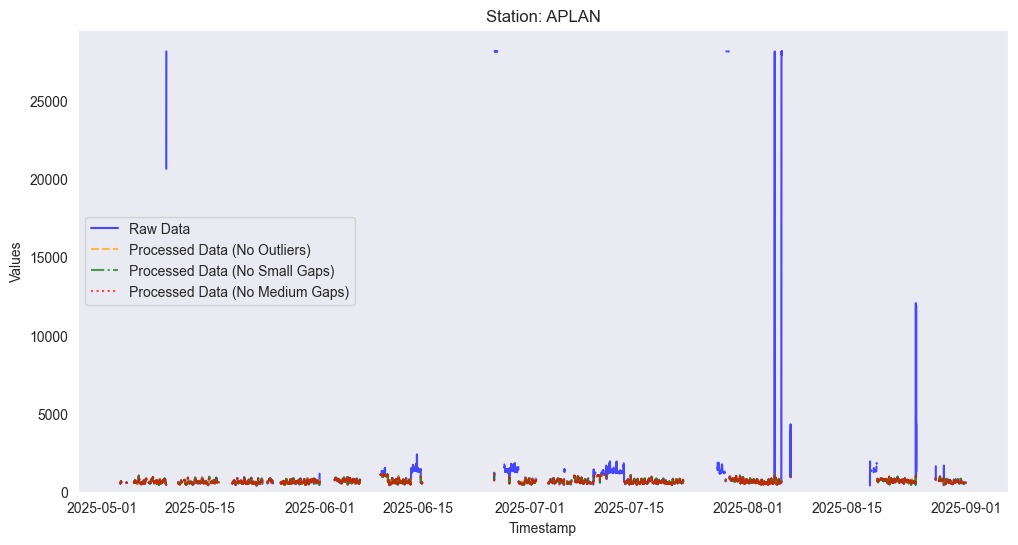

NaN values at different processing stages:
     Before Processing  After Outlier Processing  After Short Gap Processing  After Medium Gap Processing
ICA                 26                        27                          22                           22
TEM                 26                        63                          43                           36
HUM                 26                        57                          47                           40
CO2                 26                        29                          25                           22
VOC                 26                       394                         361                          331


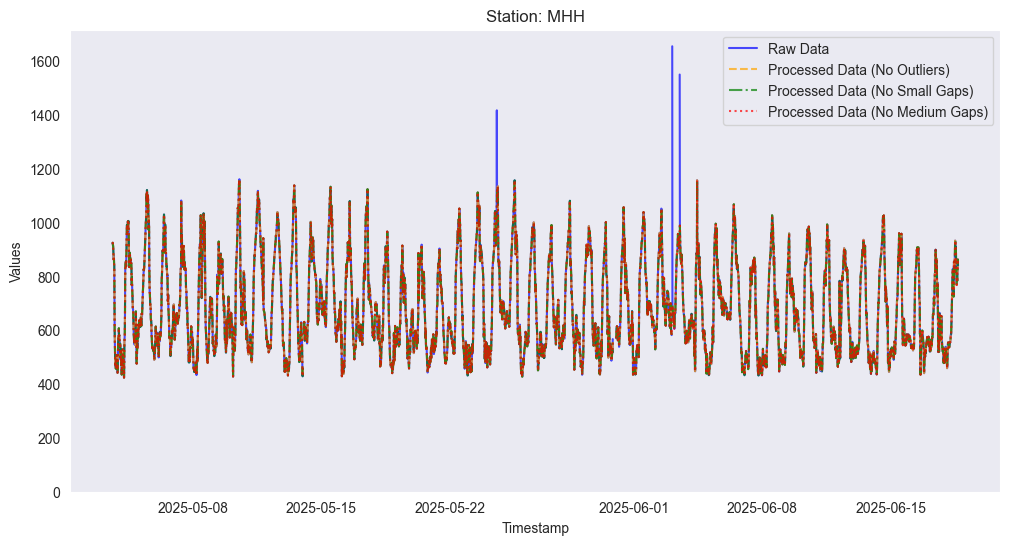

NaN values at different processing stages:
     Before Processing  After Outlier Processing  After Short Gap Processing  After Medium Gap Processing
ICA               8667                      8673                        8474                         8306
TEM               8667                      8751                        8562                         8397
HUM               8667                      8747                        8556                         8391
CO2               8667                      9073                        8878                         8713
VOC               8667                      9101                        8910                         8741


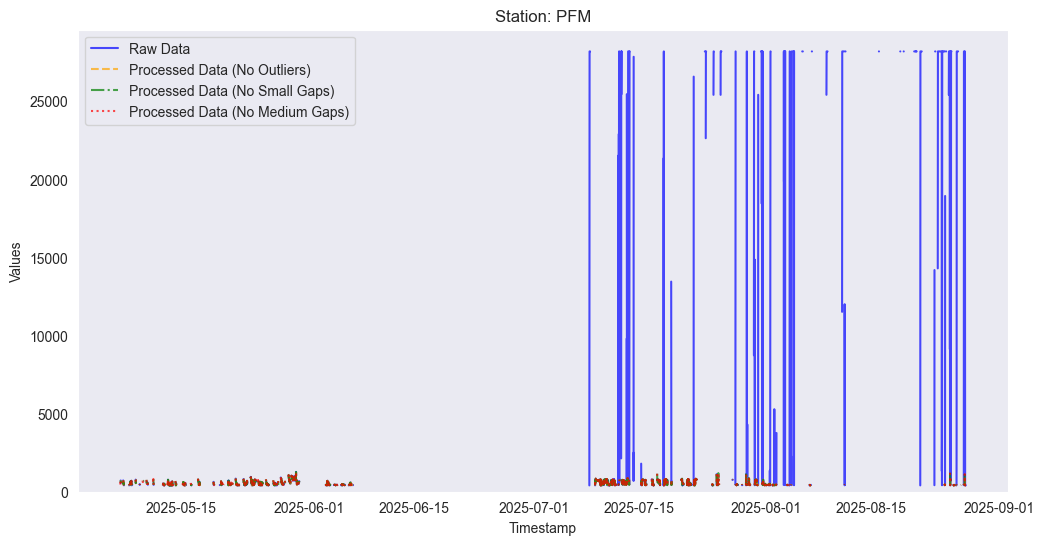

NaN values at different processing stages:
     Before Processing  After Outlier Processing  After Short Gap Processing  After Medium Gap Processing
ICA               4172                      4837                        4605                         4462
TEM               4172                      4175                        3977                         3878
HUM               4172                      4172                        3977                         3878
CO2               4172                      4417                        4202                         4093
VOC               4172                      5214                        4991                         4880


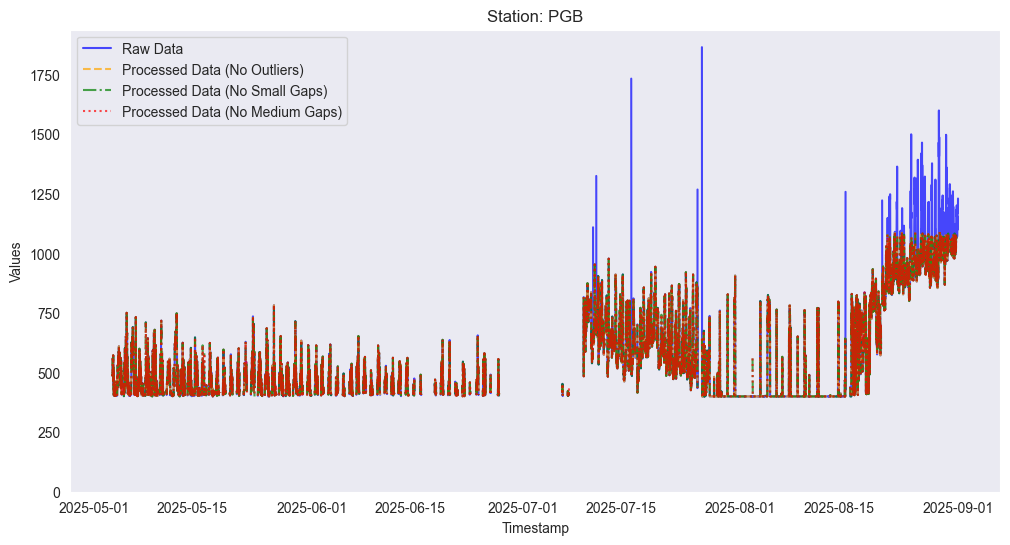

NaN values at different processing stages:
     Before Processing  After Outlier Processing  After Short Gap Processing  After Medium Gap Processing
ICA               6913                      6913                        6598                         6419
TEM               6913                      6913                        6598                         6419
HUM               6913                      6913                        6598                         6419
CO2               6913                      7003                        6702                         6528
VOC               6913                      7147                        6824                         6656


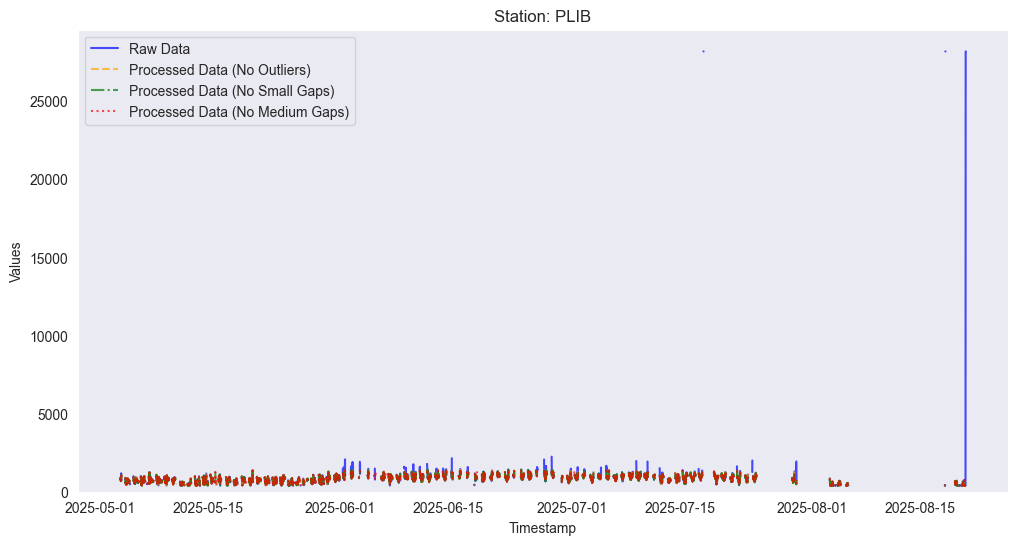

NaN values at different processing stages:
     Before Processing  After Outlier Processing  After Short Gap Processing  After Medium Gap Processing
ICA               4336                      4905                        4603                         4436
CO2               4336                      4364                        4258                         4219
VOC               4336                      4755                        4509                         4396
TEM               4336                      4339                        4247                         4216
HUM               4336                      4338                        4248                         4217


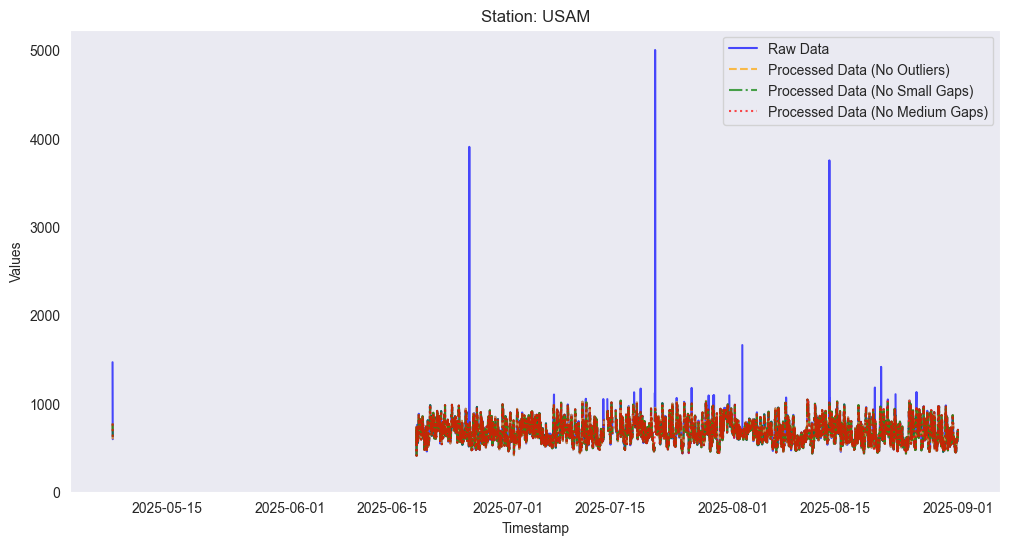

NaN values at different processing stages:
     Before Processing  After Outlier Processing  After Short Gap Processing  After Medium Gap Processing
ICA               4263                      4318                        4300                         4284
TEM               4263                      4287                        4274                         4257
HUM               4263                      4263                        4250                         4237
CO2               4263                      4371                        4333                         4300
VOC               4263                      4835                        4724                         4611


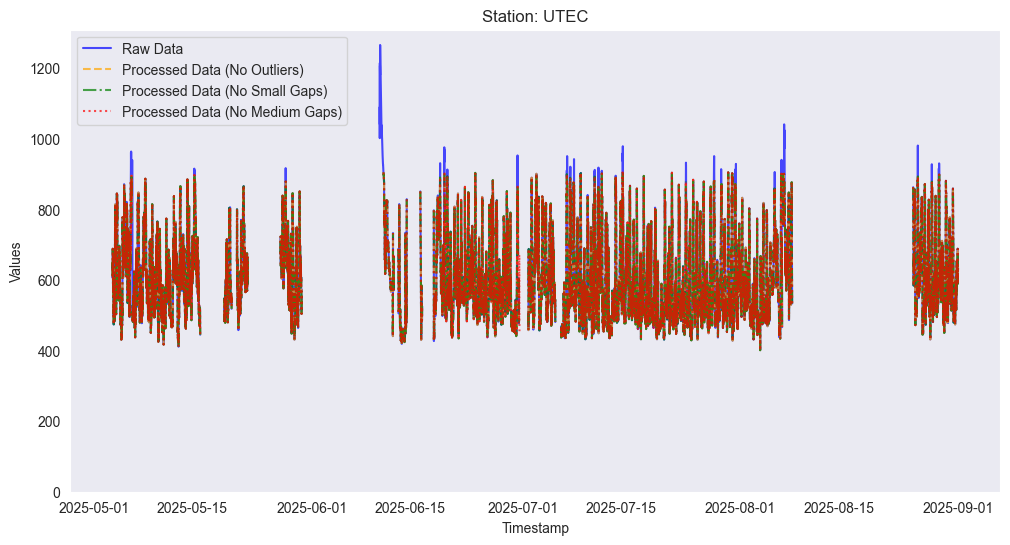

In [2]:
FREQ = pd.Timedelta("15min")
MAX_SHORT = 2   # 2 samples x 15 min = 30 min
MAX_MEDIUM = 4   # 4 samples x 15 min = 60 min
WINDOW: int = 16      # valid samples used on each side of a gap

# Load data
stations = ['APLAN','MHH','PFM', 'PGB', 'PLIB', 'USAM', 'UTEC']
generalpath = "data/air/consolidated"
output_path = "data/air/processed"

os.makedirs(output_path, exist_ok=True)  # Ensure output directory exists

raws, cleans = {}, {}
for station in stations:

    filepath = os.path.join(generalpath, f"{station}.csv")
    df = pd.read_csv(filepath, delimiter=";", parse_dates=['Timestamp'], index_col='Timestamp')
    raw = df.resample(FREQ).mean()  # Resample to 15-minute intervals

    processed_no_outlier = process_outliers(raw)

    # Mask gaps under the limit for short gaps
    short_gap_mask = mask_gaps(processed_no_outlier, min_len=0, max_len=MAX_SHORT)

    # Fill short gaps using the mask
    processed_no_gap_short = processed_no_outlier.where(~short_gap_mask, fill_short_gaps(processed_no_outlier, max_len=MAX_SHORT))

    # Mask gaps under the limit for medium gaps
    medium_gap_mask = mask_gaps(processed_no_outlier, min_len=MAX_SHORT, max_len=MAX_MEDIUM)
    processed_no_gap_medium = impute_medium_gaps(processed_no_gap_short, medium_gap_mask, window=WINDOW)

    # Save processed data as CSV and Parquet
    processed_no_gap_medium.to_csv(os.path.join(output_path, f"{station}_processed.csv"))
    processed_no_gap_medium.to_parquet(os.path.join(output_path, f"{station}_processed.parquet"))

    raws[station] = raw
    cleans[station] = processed_no_gap_medium

    pd.set_option('display.max_columns', None)  # Ensure all columns are displayed
    pd.set_option('display.width', 1000)       # Set a wide display width

    nan_counts = pd.DataFrame({
        "Before Processing": raw.isna().sum(),
        "After Outlier Processing": processed_no_outlier.isna().sum(),
        "After Short Gap Processing": processed_no_gap_short.isna().sum(),
        "After Medium Gap Processing": processed_no_gap_medium.isna().sum()
    })

    print("NaN values at different processing stages:")
    print(nan_counts)

       # Plot raw, processed_no_outlier, and processed_no_gap
    plot_dataframes(
        [raw, processed_no_outlier, processed_no_gap_short, processed_no_gap_medium],
        station=station,
        column='CO2',
        labels=['Raw Data', 'Processed Data (No Outliers)', 'Processed Data (No Small Gaps)', 'Processed Data (No Medium Gaps)']
    )



### 1.3 Checking the processed CSV and Parquet Files

PGB
ICA    4462
TEM    3878
HUM    3878
CO2    4093
VOC    4880
dtype: int64


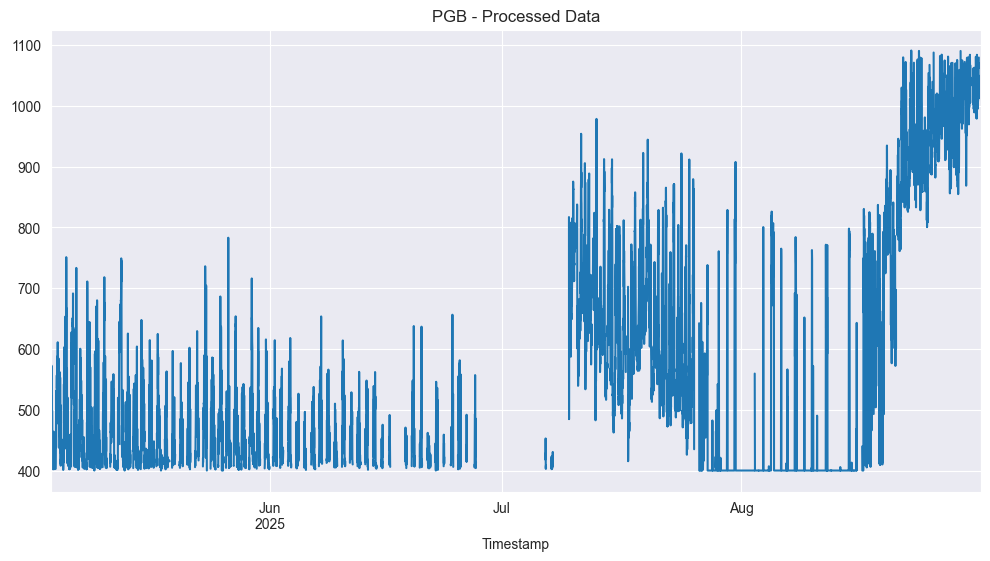

PLIB
ICA    6419
TEM    6419
HUM    6419
CO2    6528
VOC    6656
dtype: int64


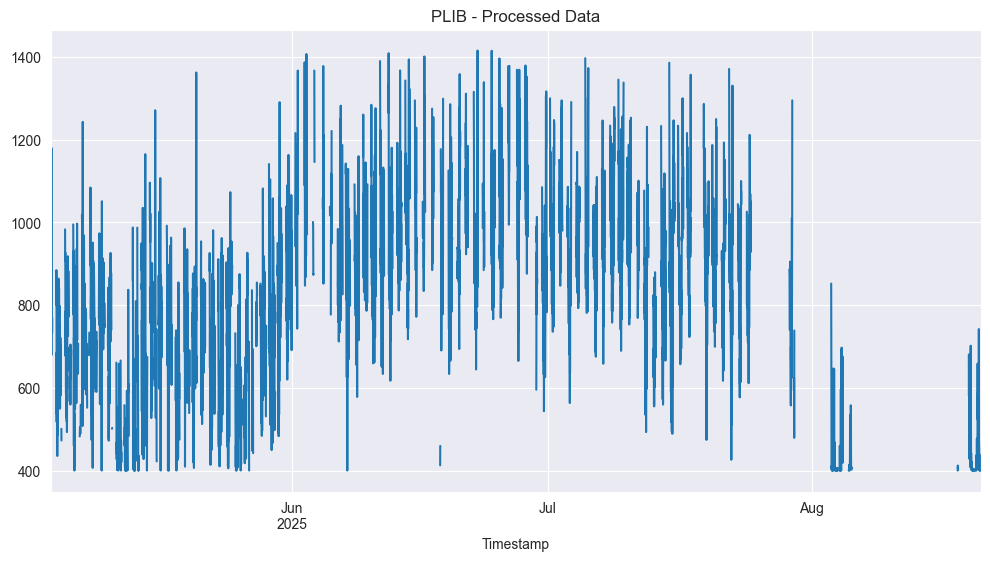

USAM
ICA    4436
CO2    4219
VOC    4396
TEM    4216
HUM    4217
dtype: int64


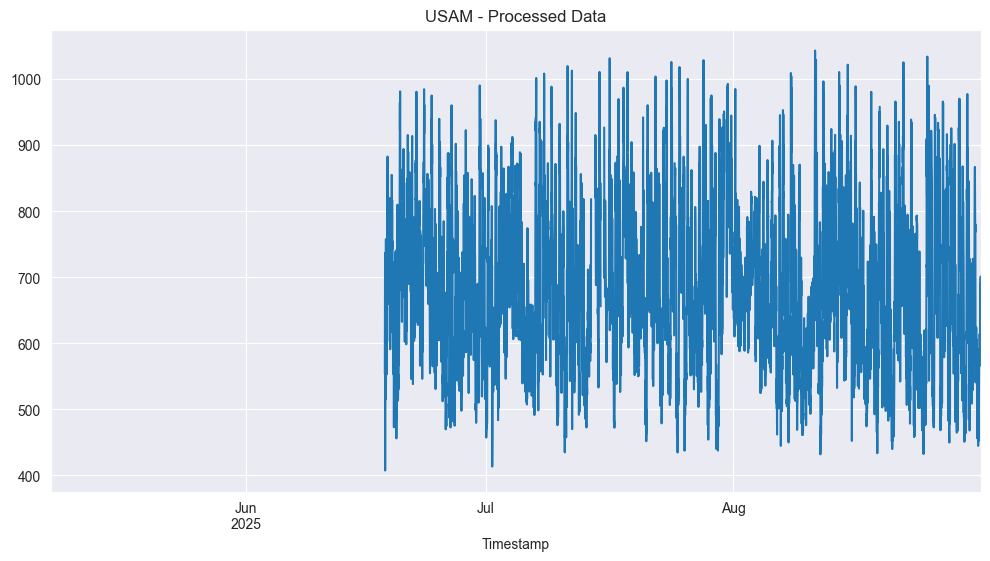

UTEC
ICA    4284
TEM    4257
HUM    4237
CO2    4300
VOC    4611
dtype: int64


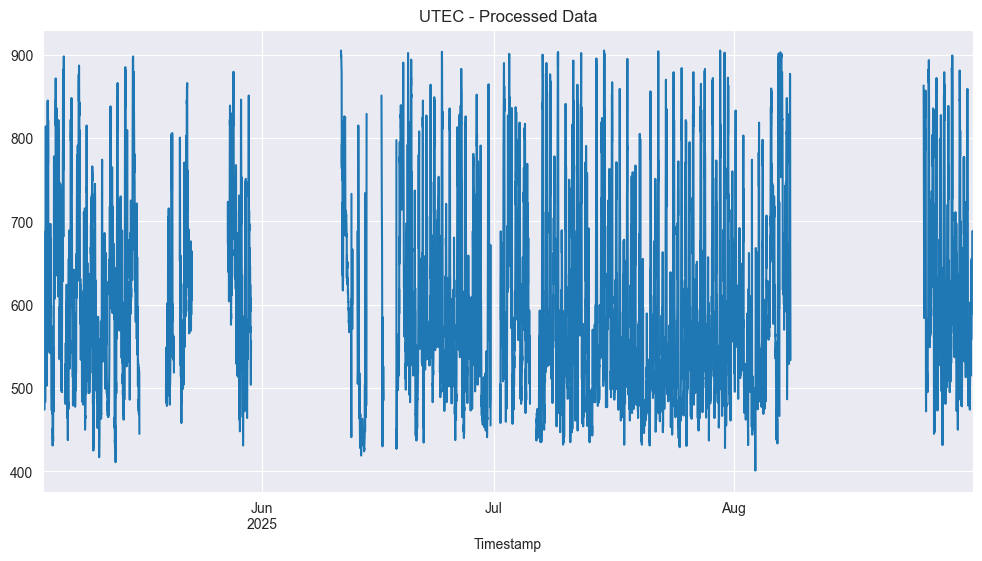

In [3]:
# Load data
stations = ['PGB', 'PLIB', 'USAM', 'UTEC']
generalpath =  "data/air/processed"

for station in stations:

    filepath = os.path.join(generalpath, f"{station}_processed.parquet")
    df_parquet = pd.read_parquet(filepath)
    print(station)
    print(df_parquet.isna().sum())

    # Plot raw, processed_no_outlier, and processed_no_gap
    df_parquet['CO2'].plot(title=f"{station} - Processed Data", figsize=(12, 6))
    plt.show()


PGB
Timestamp       0
ICA          4462
TEM          3878
HUM          3878
CO2          4093
VOC          4880
dtype: int64


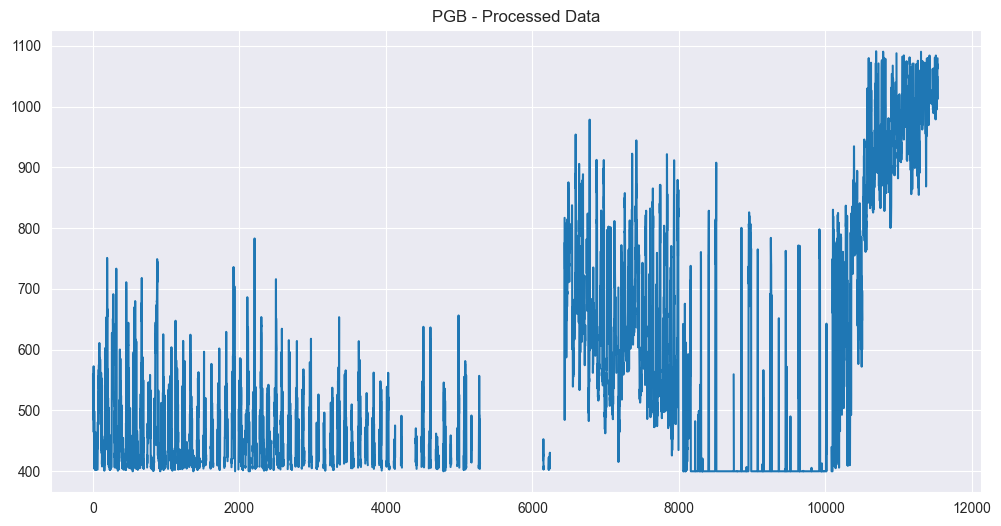

PLIB
Timestamp       0
ICA          6419
TEM          6419
HUM          6419
CO2          6528
VOC          6656
dtype: int64


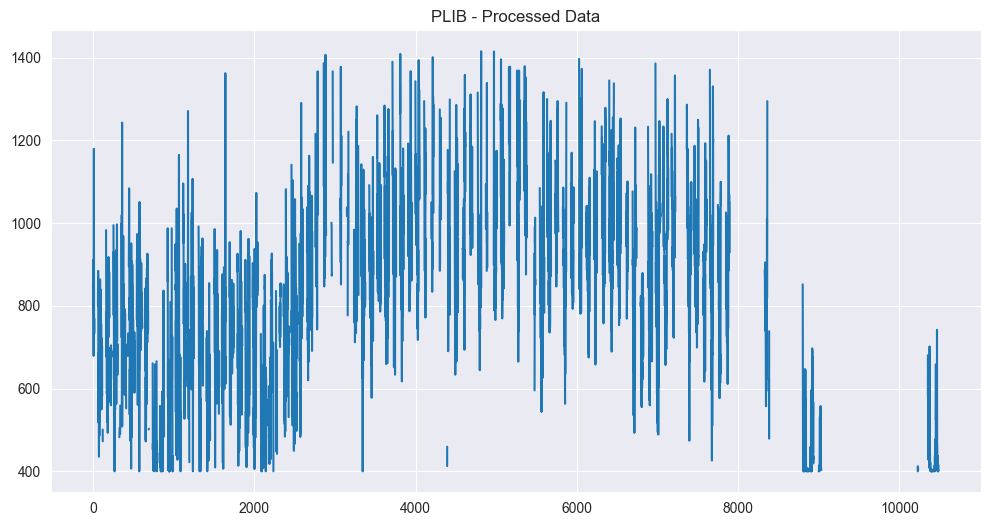

USAM
Timestamp       0
ICA          4436
CO2          4219
VOC          4396
TEM          4216
HUM          4217
dtype: int64


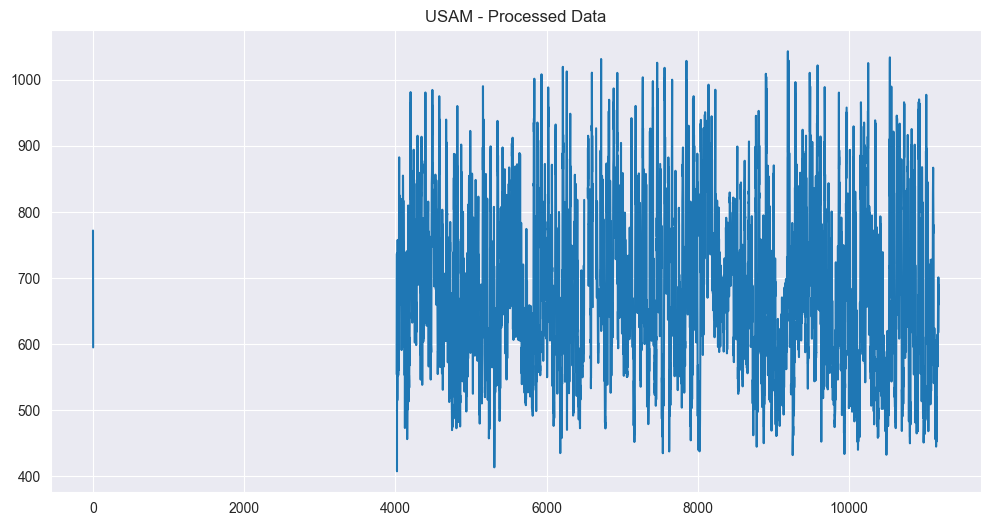

UTEC
Timestamp       0
ICA          4284
TEM          4257
HUM          4237
CO2          4300
VOC          4611
dtype: int64


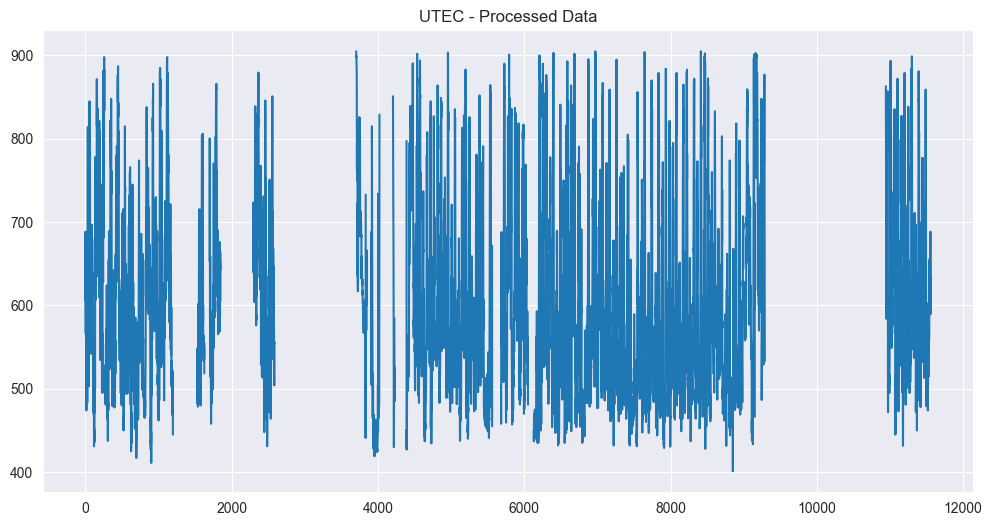

In [4]:
# Load data
stations = ['PGB', 'PLIB', 'USAM', 'UTEC']
generalpath =  "data/air/processed"

for station in stations:

    filepath = os.path.join(generalpath, f"{station}_processed.csv")
    df_csv = pd.read_csv(filepath)
    print(station)
    print(df_csv.isna().sum())

    # Plot raw, processed_no_outlier, and processed_no_gap
    df_csv['CO2'].plot(title=f"{station} - Processed Data", figsize=(12, 6))
    plt.show()

## 2 - Data exploration processed data

### 2.1 Functions for data exploration: raw and processed

In [10]:
"""Exploratory analysis of the cleaned station data (15-min grid)."""

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.seasonal import STL

sns.set_theme(style="whitegrid")


# 1. Distributions -----------------------------------------------------------
def plot_distributions(clean: pd.DataFrame) -> None:
    """Histograms and boxplots per column, and skewness."""
    n = len(clean.columns)
    fig, axes = plt.subplots(2, n, figsize=(3.2 * n, 6))
    for i, col in enumerate(clean.columns):
        sns.histplot(clean[col], bins=50, ax=axes[0, i])
        sns.boxplot(y=clean[col], ax=axes[1, i])
    fig.tight_layout()
    print("Skewness:\n", clean.skew().round(2))


# 2. Temporal patterns -------------------------------------------------------
DAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

def plot_temporal_patterns(clean: pd.DataFrame, col: str) -> None:
    """Hourly profile with quantile band, weekday profile, heatmap."""
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    by_hour = clean[col].groupby(clean.index.hour)
    median = by_hour.median()
    axes[0].plot(median.index, median, label="median")
    axes[0].fill_between(median.index, by_hour.quantile(0.1),
                         by_hour.quantile(0.9), alpha=0.3, label="10-90 %")
    axes[0].set(title=f"{col} by hour", xlabel="hour")
    axes[0].legend()

    by_day = clean[col].groupby(clean.index.dayofweek).mean()
    by_day.index = [DAYS[i] for i in by_day.index]
    by_day.plot.bar(ax=axes[1], rot=0)
    axes[1].set(title=f"{col} by weekday")

    pivot = (clean[col]
             .groupby([clean.index.dayofweek, clean.index.hour])
             .mean().unstack())
    pivot.index = [DAYS[i] for i in pivot.index]
    sns.heatmap(pivot, cmap="viridis", ax=axes[2])
    axes[2].set(title=f"{col}: weekday x hour", xlabel="hour",
                ylabel="")
    axes[2].tick_params(axis="y", rotation=0)
    fig.tight_layout()


# 3. Correlations -----------------------------------------------------------
def plot_correlations(clean: pd.DataFrame) -> None:
    """Spearman correlation (raw) + pairplot."""
    fig, ax = plt.subplots(figsize=(6, 4.5))
    sns.heatmap(clean.corr(method="spearman"), annot=True, fmt=".2f",
                cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax)
    ax.set_title("Spearman")
    fig.tight_layout()

    sns.pairplot(clean.sample(min(len(clean), 3000), random_state=0),
                 corner=True, plot_kws={"s": 6, "alpha": 0.4})
    plt.show()

def plot_correlations_features(
    clean: pd.DataFrame,
    method: str = "spearman",
    annot: bool | None = None,        # None = auto (on if <= 25 variables)
    cluster: bool = False,            # reorder variables so correlated ones sit together
    pairplot_cols: list | None = None,  # subset for the pairplot; None = skip it
    sample_size: int = 3000,
) -> None:
    """Correlation heatmap (lower triangle) + optional pairplot of selected variables."""
    corr = clean.corr(method=method)
    n = len(corr)

    # Optional: hierarchical ordering so correlated groups form visible blocks
    if cluster:
        from scipy.cluster.hierarchy import linkage, leaves_list
        from scipy.spatial.distance import squareform
        dist = 1 - corr.abs().to_numpy()
        np.fill_diagonal(dist, 0)
        order = leaves_list(linkage(squareform(dist, checks=False), "average"))
        corr = corr.iloc[order, order]

    if annot is None:
        annot = n <= 25

    # Size scales with the number of variables
    side = max(7, 0.55 * n + 2)
    fig, ax = plt.subplots(figsize=(side, side * 0.85))

    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)   # hide the redundant upper triangle
    sns.heatmap(
        corr, mask=mask, ax=ax,
        annot=annot, fmt=".2f", annot_kws={"size": max(5, 11 - n // 3)},
        cmap="coolwarm", center=0, vmin=-1, vmax=1,
        square=True, linewidths=0.4, linecolor="white",
        cbar_kws={"shrink": 0.7, "label": method.capitalize()},
    )
    ax.set_title(f"{method.capitalize()} correlation")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    plt.setp(ax.get_yticklabels(), rotation=0)
    fig.tight_layout()

    # Pairplot only for a chosen subset (20x20 panels is unreadable)
    if pairplot_cols:
        sample = clean[pairplot_cols].sample(min(len(clean), sample_size), random_state=0)
        sns.pairplot(sample, corner=True, plot_kws={"s": 6, "alpha": 0.4})

    plt.show()


### 2.2 Data Exploration

**Plot Distribution**

Skewness:
 ICA    1.42
TEM    0.31
HUM    0.35
CO2    0.93
VOC    1.39
dtype: float64
Skewness:
 ICA    0.44
TEM    0.78
HUM   -1.12
CO2    0.56
VOC    1.37
dtype: float64
Skewness:
 ICA    0.63
CO2    0.31
VOC    0.92
TEM    0.56
HUM   -0.54
dtype: float64
Skewness:
 ICA    0.32
TEM    0.58
HUM   -0.17
CO2    0.78
VOC    1.06
dtype: float64


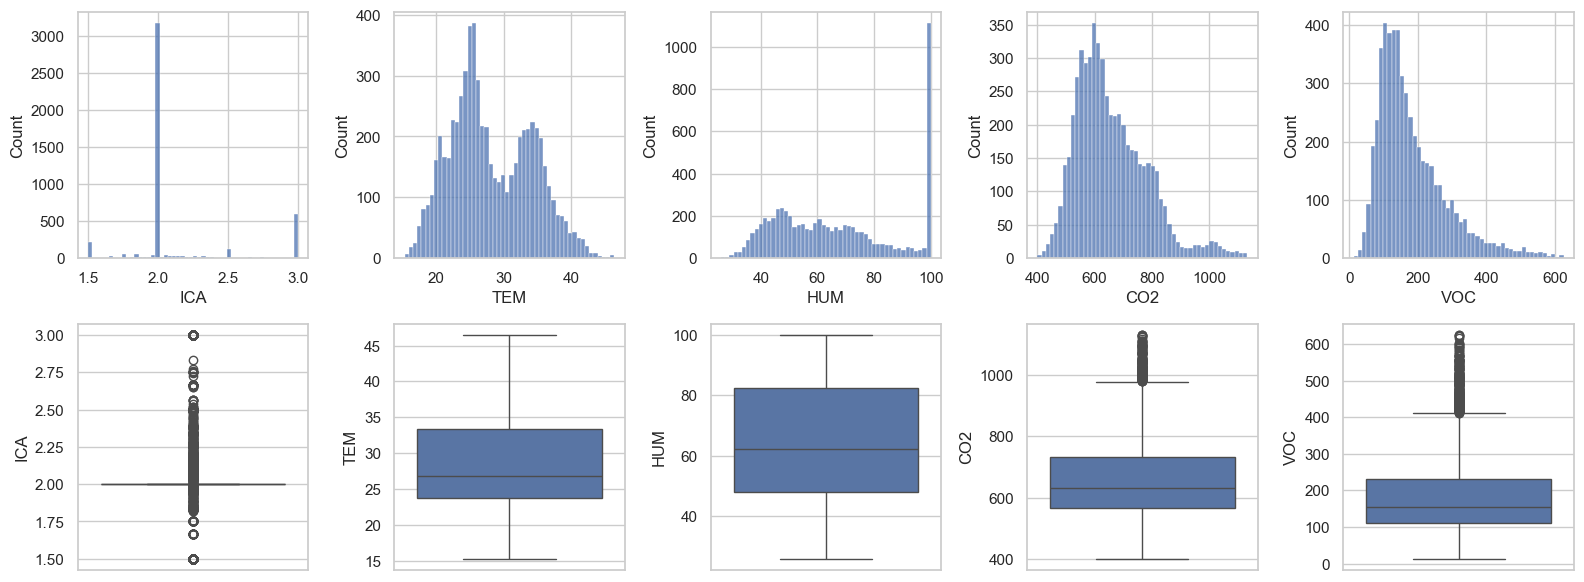

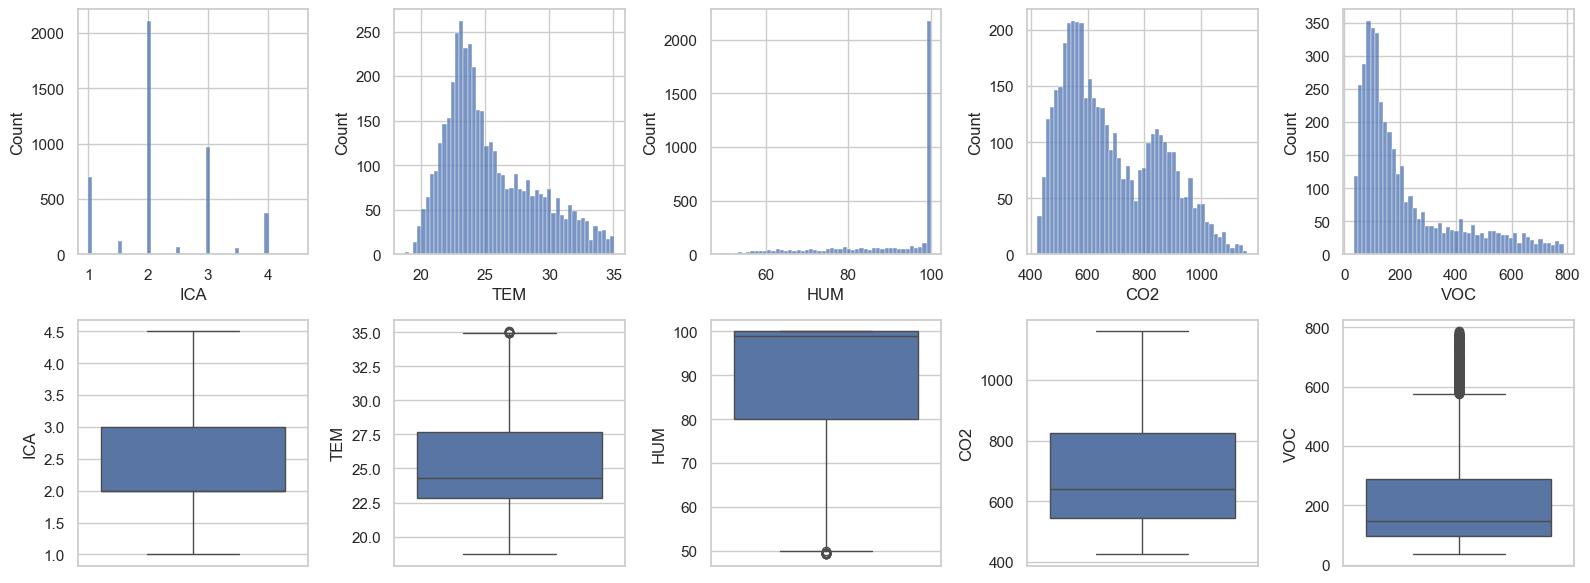

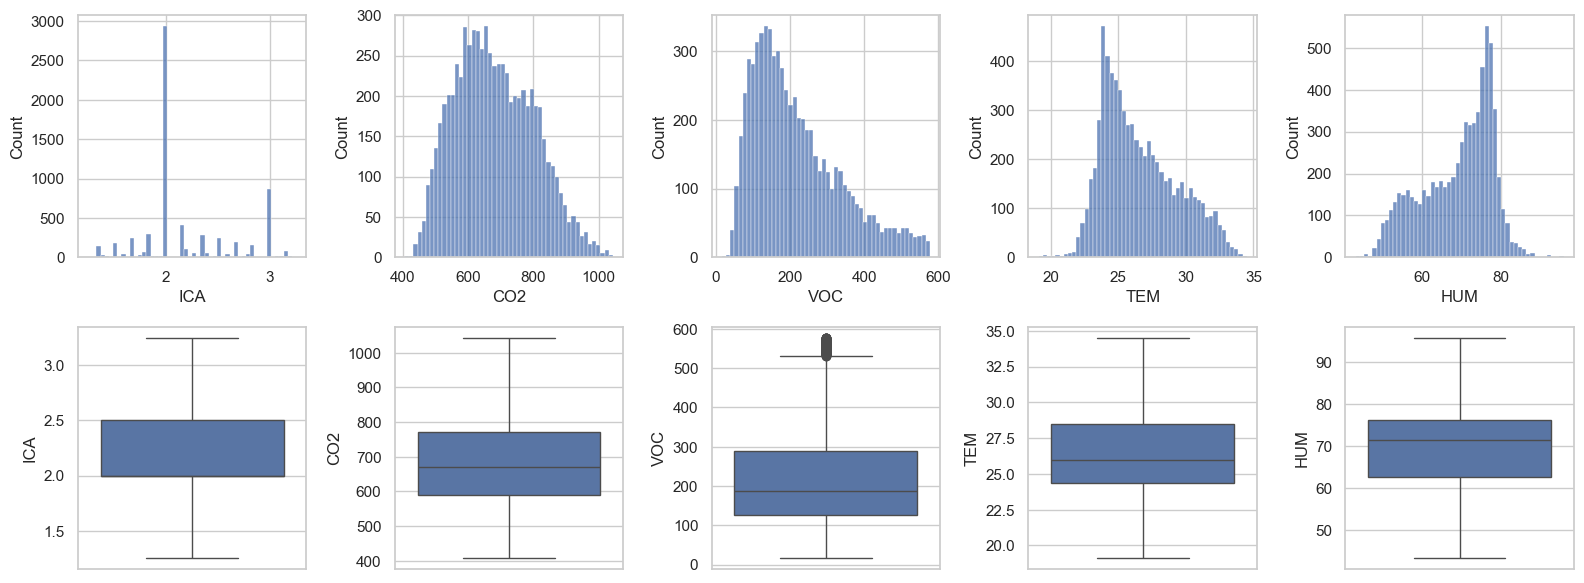

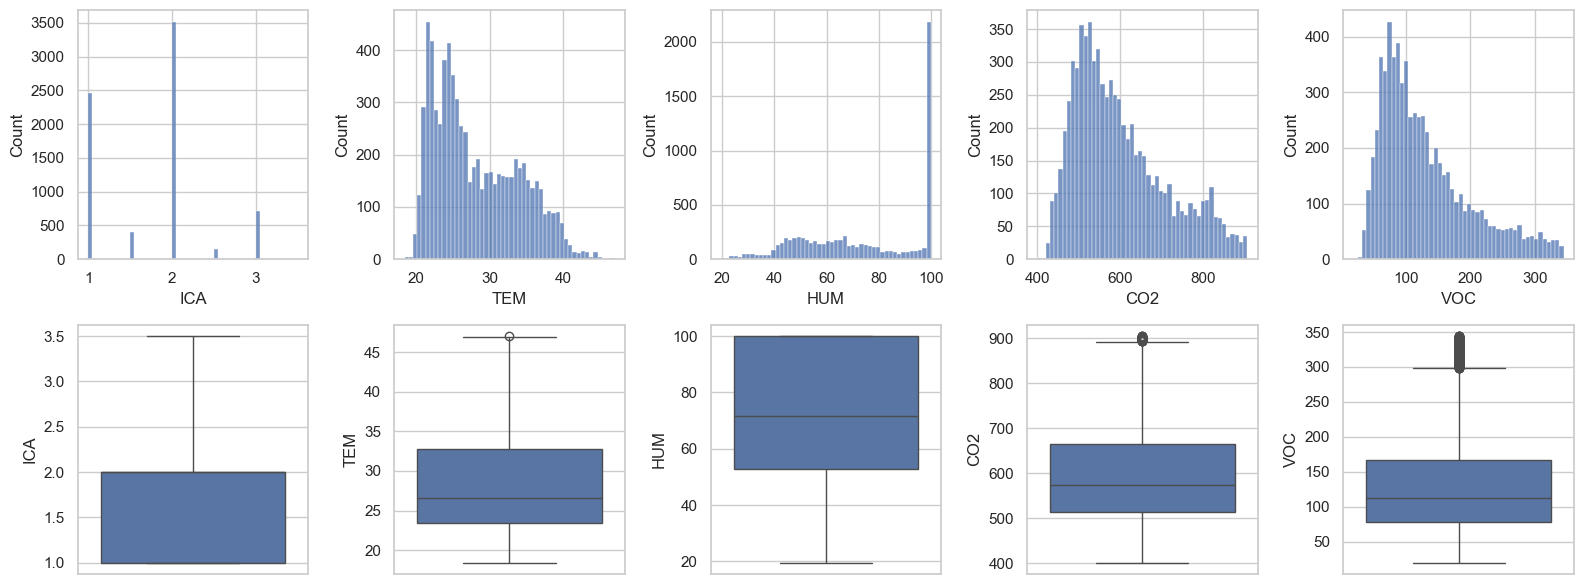

In [6]:
stations = ['APLAN','MHH', 'USAM', 'UTEC']
# stations = ['APLAN','MHH','PFM', 'PGB', 'PLIB', 'USAM', 'UTEC']

for station in stations:
    print("station: ",station)
    plot_distributions(cleans[station])



**Plot temporal patterns**

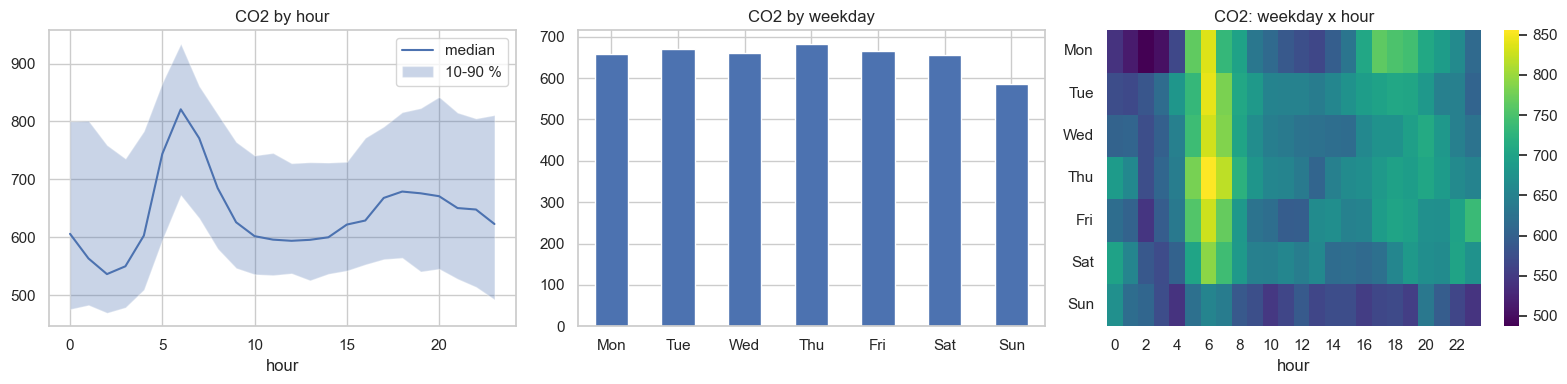

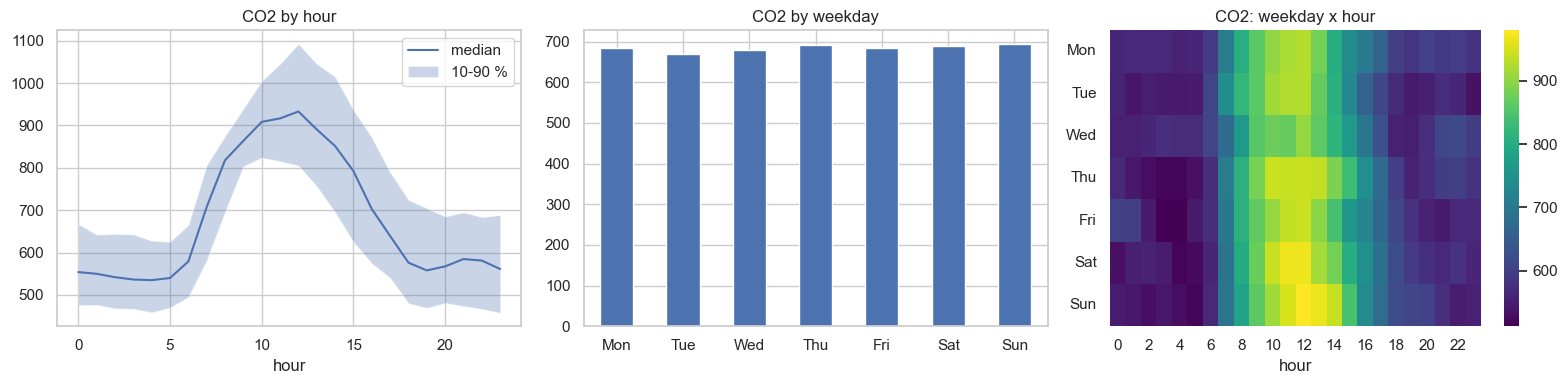

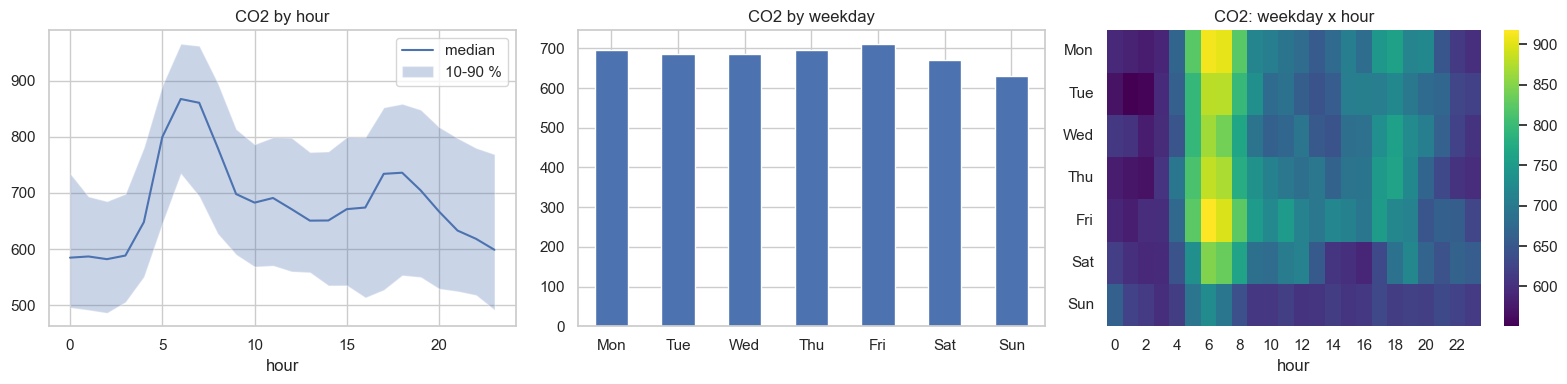

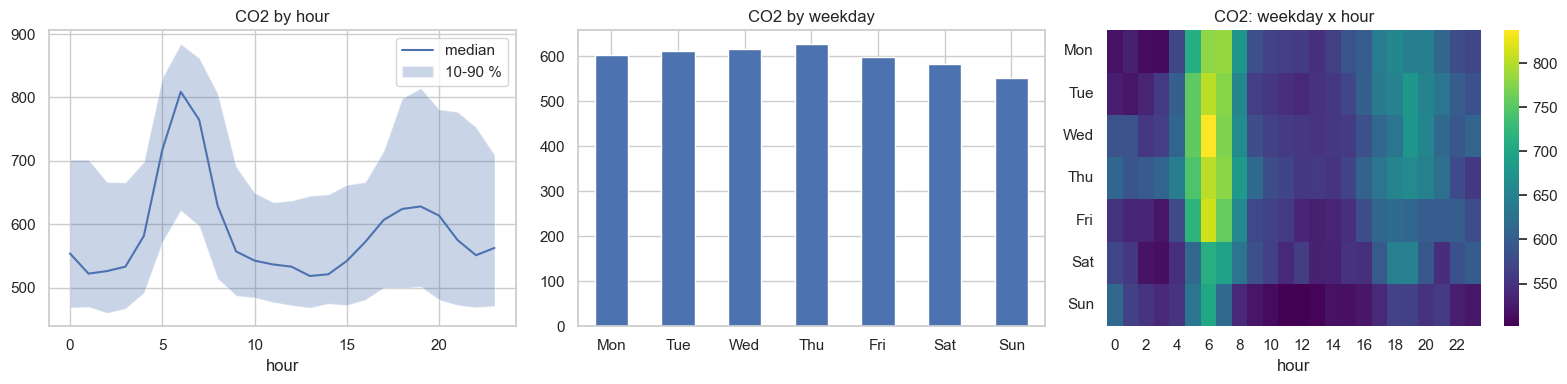

In [9]:
stations = ['APLAN','MHH', 'USAM', 'UTEC']
# stations = ['APLAN','MHH','PFM', 'PGB', 'PLIB', 'USAM', 'UTEC']

for station in stations:
    plot_temporal_patterns(cleans[station], col="CO2")

**Correlations**

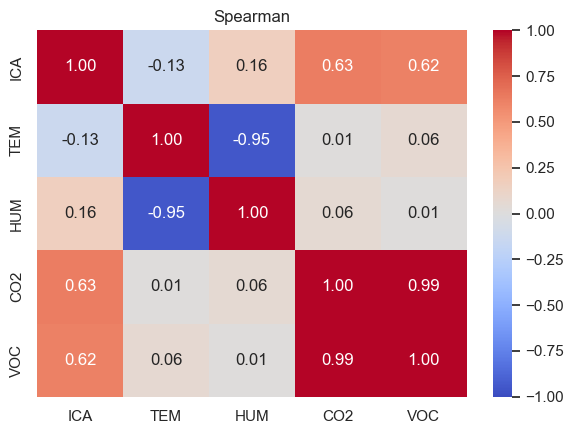

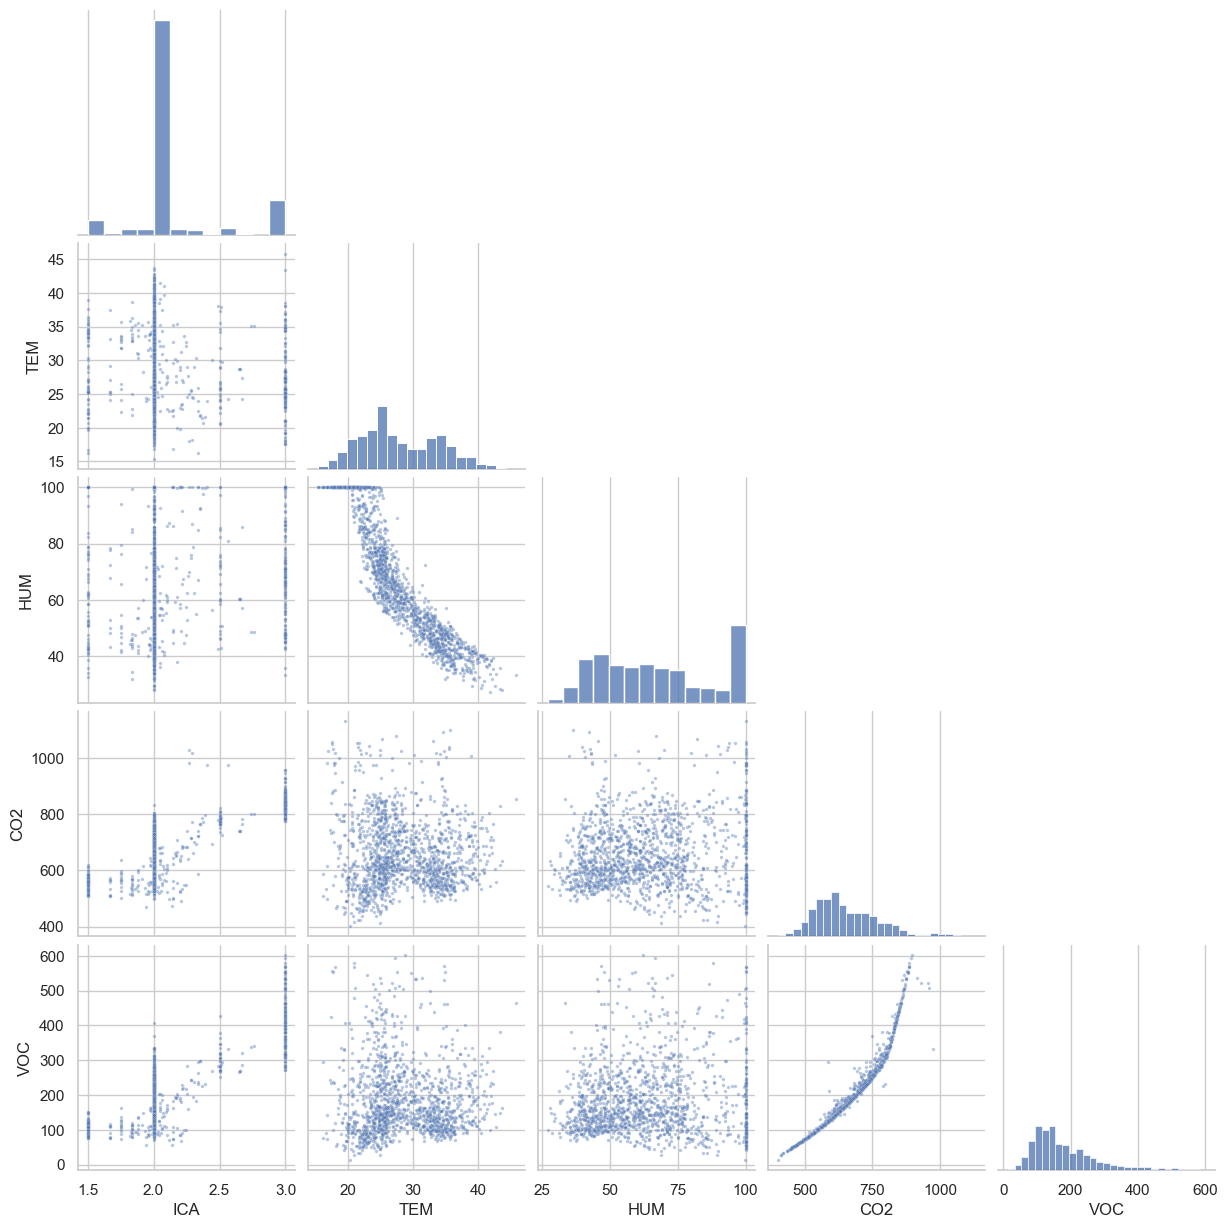

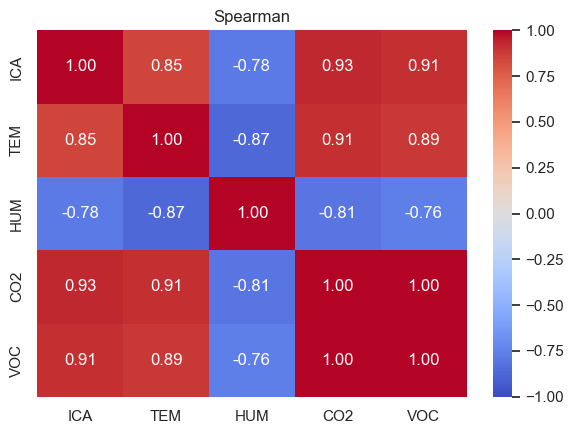

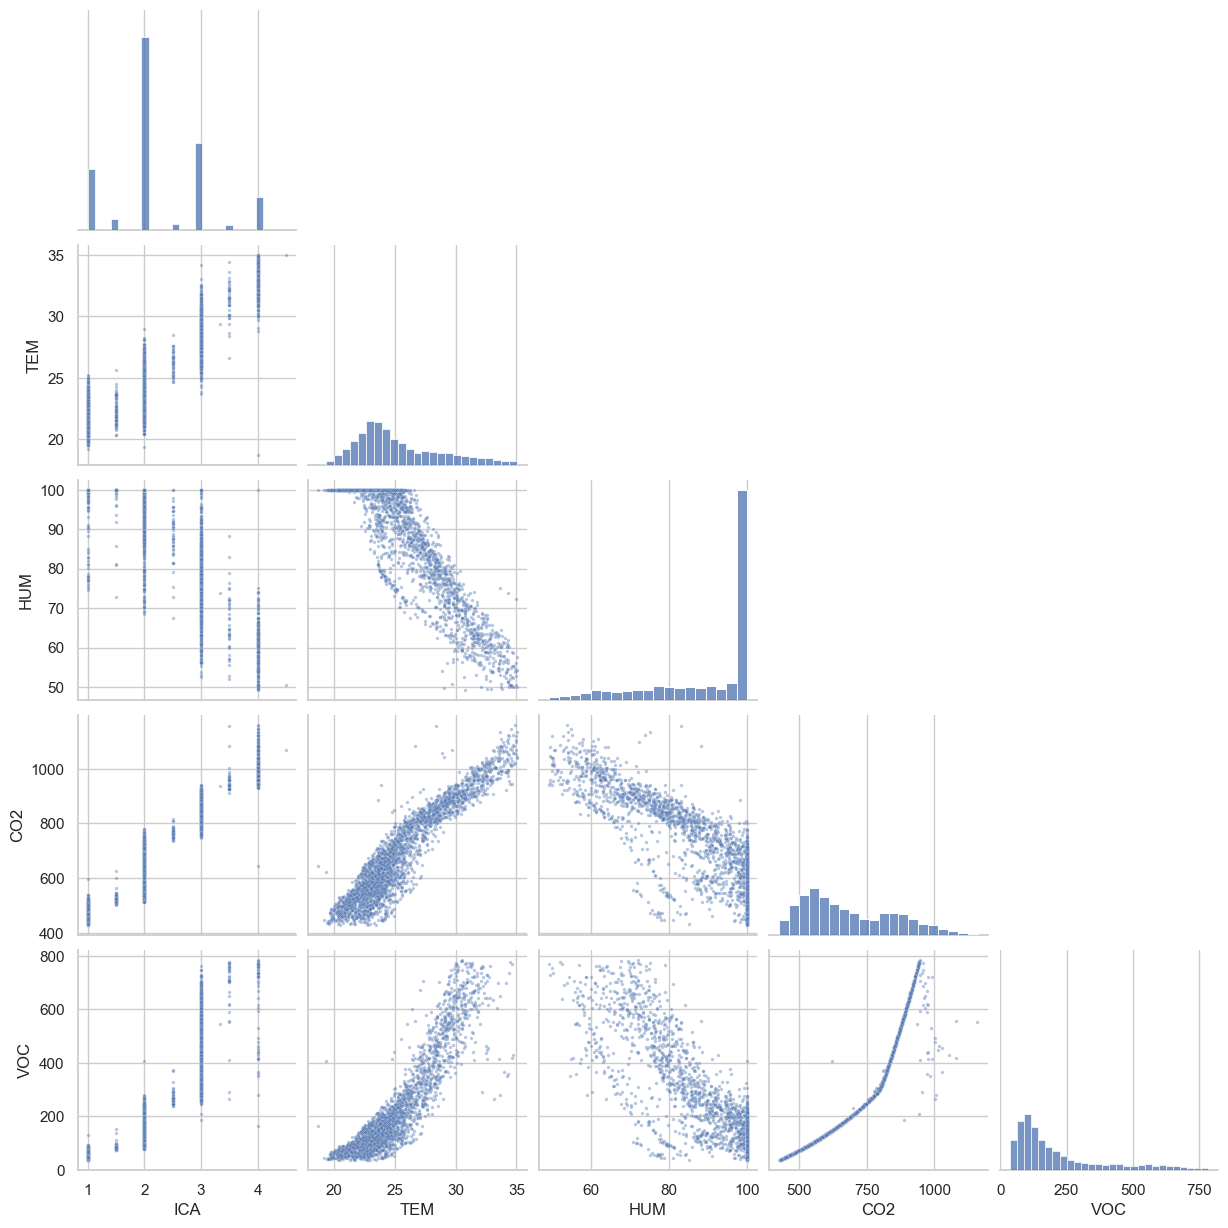

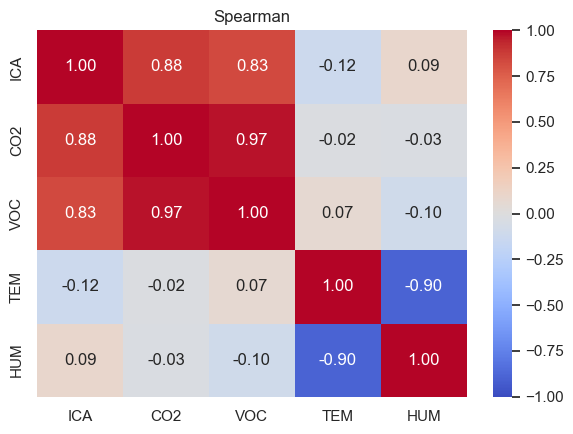

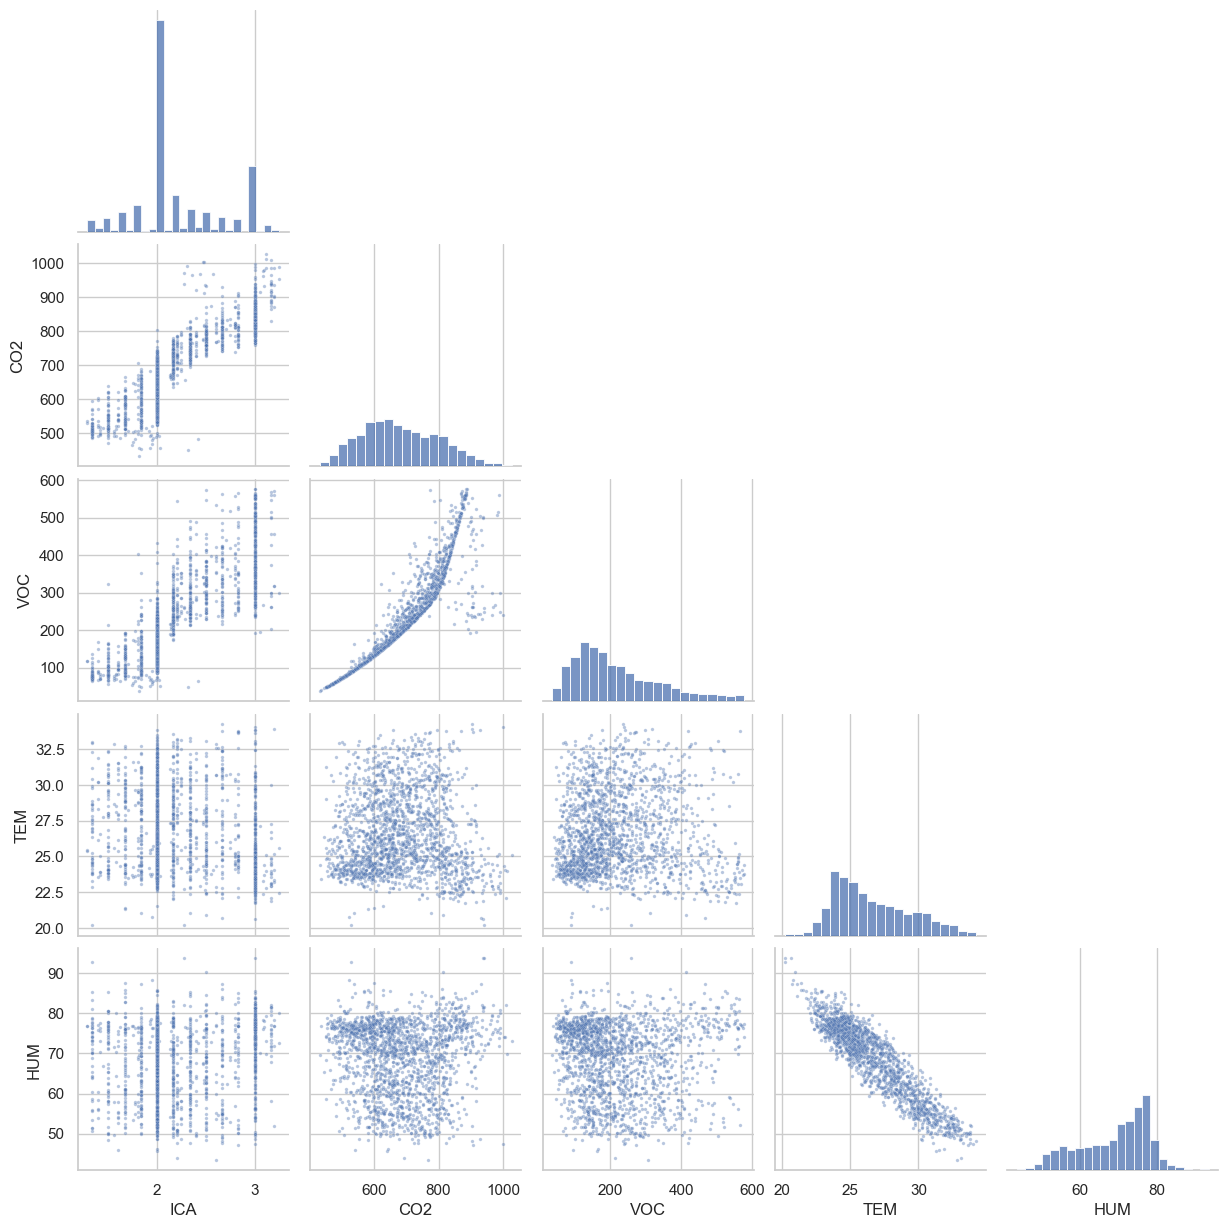

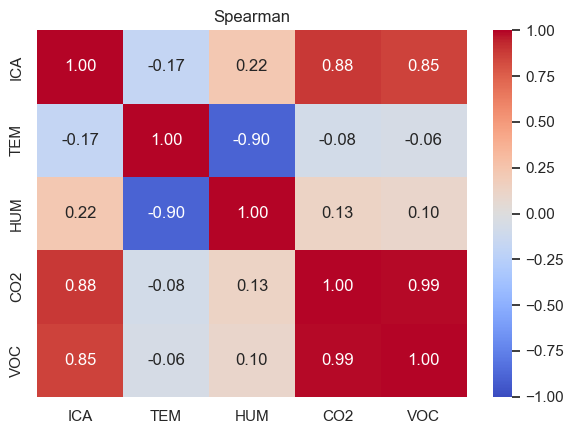

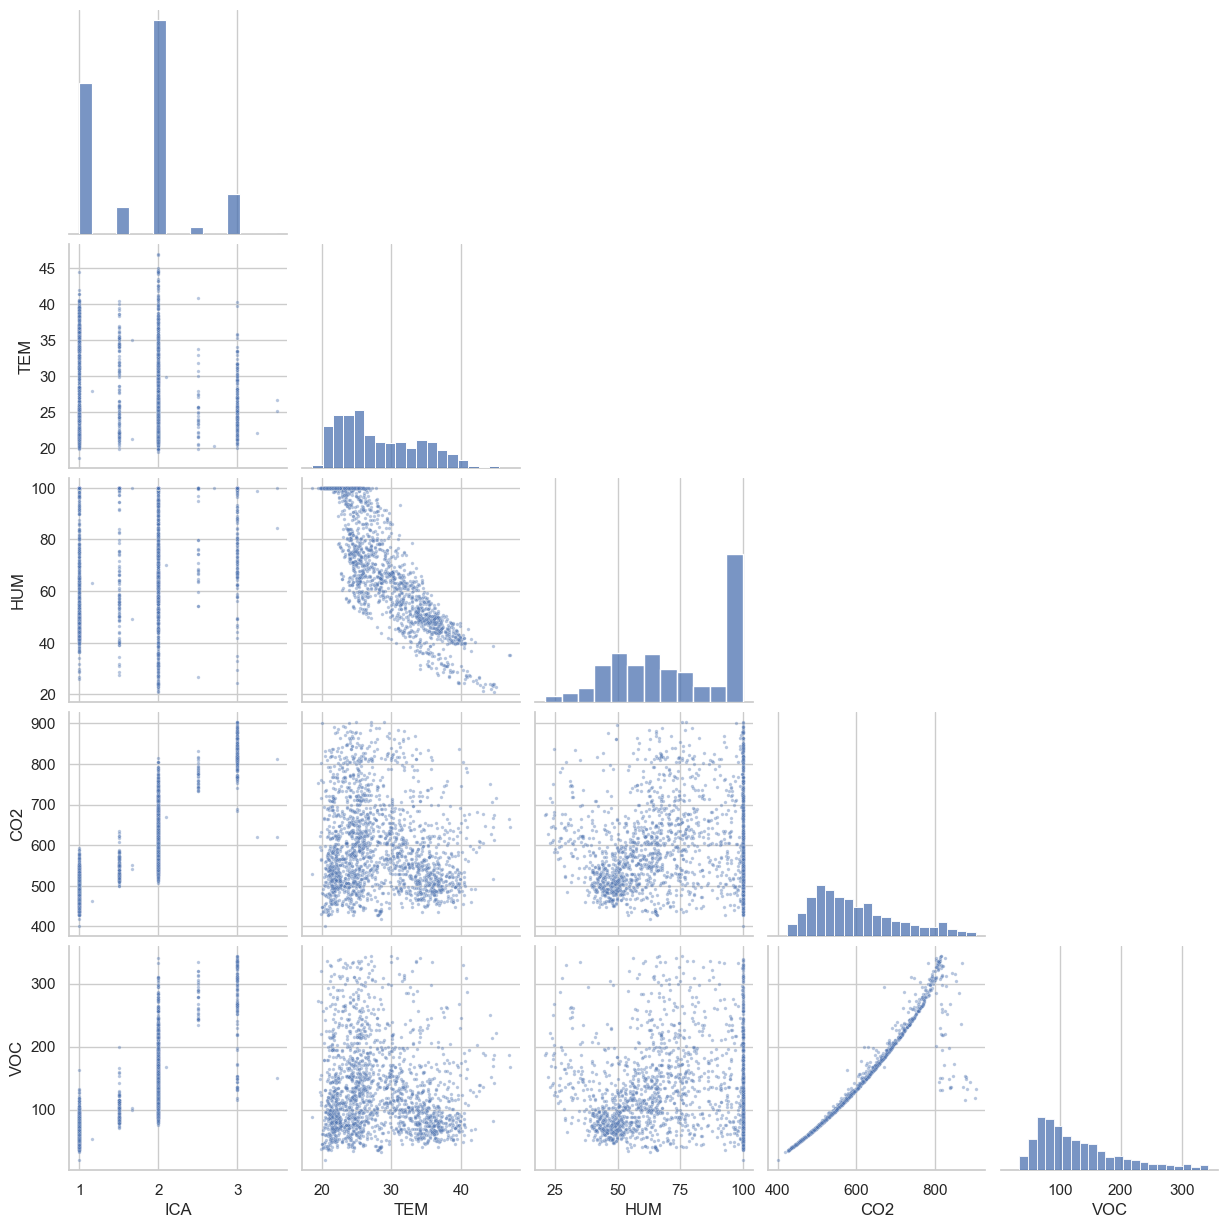

In [12]:
stations = ['APLAN','MHH', 'USAM', 'UTEC']
# stations = ['APLAN','MHH','PFM', 'PGB', 'PLIB', 'USAM', 'UTEC']

for station in stations:
    plot_correlations(cleans[station])

## 3 - Feature generation

In [5]:
import numpy as np

def generate_features(
    df: pd.DataFrame,
    cols=("TEM", "HUM", "VOC", "CO2"),
    lags=(1, 2, 3, 6, 12, 24),
    rolling_windows=(6, 24),
    rolling_stats=("mean", "std"),        # any of: mean, std, min, max
    harmonics=(1, 2),                     # number of sin/cos pairs for hour of day
    weekend_flag: bool = True,
    dropna: bool = True,
) -> pd.DataFrame:

    df = df.sort_index().copy()           # index is already a DatetimeIndex named "Timestamp"
    idx = df.index

    # --- Temporal features ---
    hour_frac = (idx.hour * 3600 + idx.minute * 60 + idx.second) / 86400  # 0..1
    dow_frac = (idx.dayofweek + hour_frac) / 7                            # 0..1, Monday = 0

    feats = {}
    for k in harmonics:
        feats[f"hour_sin{k}"] = np.sin(2 * np.pi * k * hour_frac)
        feats[f"hour_cos{k}"] = np.cos(2 * np.pi * k * hour_frac)

    feats["dow_sin"] = np.sin(2 * np.pi * dow_frac)
    feats["dow_cos"] = np.cos(2 * np.pi * dow_frac)

    if weekend_flag:
        feats["is_weekend"] = (idx.dayofweek >= 5).astype(int)

    # --- Lag and rolling features for each variable ---
    for col in cols:
        # Lags: single past values
        for lag in lags:
            feats[f"{col}_lag{lag}"] = df[col].shift(lag)

        # Rolling: statistics over the previous w rows (shift(1) excludes the current value)
        past = df[col].shift(1)
        for w in rolling_windows:
            roll = past.rolling(w)
            for stat in rolling_stats:
                feats[f"{col}_roll_{stat}{w}"] = getattr(roll, stat)()

    out = pd.concat([df, pd.DataFrame(feats, index=idx)], axis=1)

    if dropna:
        out = out.dropna()   # removes the first max(max(lags), max(rolling_windows)) + 1 rows

    return out

In [6]:
import os
import pandas as pd

# Load data
stations = ['APLAN','MHH','PFM', 'PGB', 'PLIB', 'USAM', 'UTEC']
generalpath = "data/air/processed"
output_path = "data/air/processed"

os.makedirs(output_path, exist_ok=True)  # Ensure output directory exists


for station in stations:

    filepath = os.path.join(generalpath, f"{station}_processed.parquet")
    df = pd.read_parquet(filepath)

    data = generate_features(df)

    # Save processed data as CSV and Parquet
    data.to_csv(os.path.join(output_path, f"{station}_processed_features.csv"))
    data.to_parquet(os.path.join(output_path, f"{station}_processed_features.parquet"))


In [8]:
data

,ICA,TEM,HUM,CO2,VOC,hour_sin1,hour_cos1,hour_sin2,hour_cos2,dow_sin,...,CO2_lag1,CO2_lag2,CO2_lag3,CO2_lag6,CO2_lag12,CO2_lag24,CO2_roll_mean6,CO2_roll_std6,CO2_roll_mean24,CO2_roll_std24
Timestamp,,,,,,,,,,,,,,,,,,,,,
2025-05-03 21:00:00+00:00,2.0,25.440,57.645,603.0,134.5,-0.707107,0.707107,-1.000000,-4.286264e-16,-0.846724,...,541.0,533.0,576.0,509.5,569.0,635.0,529.666667,27.665261,570.041667,62.205990
2025-05-03 21:15:00+00:00,1.0,24.960,55.150,541.0,96.0,-0.659346,0.751840,-0.991445,1.305262e-01,-0.841713,...,603.0,541.0,533.0,497.0,505.5,650.0,545.250000,38.316772,568.708333,61.085990
2025-05-03 21:30:00+00:00,1.0,24.890,55.295,499.0,71.5,-0.608761,0.793353,-0.965926,2.588190e-01,-0.836628,...,541.0,603.0,541.0,521.5,532.0,606.0,552.583333,30.686180,564.166667,58.788062
2025-05-03 21:45:00+00:00,1.0,24.630,58.070,483.0,64.0,-0.555570,0.831470,-0.923880,3.826834e-01,-0.831470,...,499.0,541.0,603.0,576.0,483.0,688.5,548.833333,36.135394,559.708333,59.530211
2025-05-03 22:00:00+00:00,1.0,24.380,59.125,487.0,65.5,-0.500000,0.866025,-0.866025,5.000000e-01,-0.826239,...,483.0,499.0,541.0,533.0,474.0,668.0,533.333333,41.673333,551.145833,54.790407
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-08-31 22:45:00+00:00,2.0,28.675,89.435,688.5,196.5,-0.321439,0.946930,-0.608761,7.933533e-01,-0.046733,...,656.0,623.5,592.0,606.5,607.0,544.0,616.916667,21.825253,599.020833,35.996219
2025-08-31 23:00:00+00:00,2.0,28.310,87.820,641.0,161.0,-0.258819,0.965926,-0.500000,8.660254e-01,-0.037391,...,688.5,656.0,623.5,608.0,604.5,553.5,630.583333,35.430801,605.041667,38.397780
2025-08-31 23:15:00+00:00,2.0,28.150,87.855,589.5,125.5,-0.195090,0.980785,-0.382683,9.238795e-01,-0.028046,...,641.0,688.5,656.0,615.5,604.0,579.0,636.083333,33.745247,608.687500,37.433074


In [9]:
data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 5616 entries, 2025-05-03 21:00:00+00:00 to 2025-08-31 23:45:00+00:00
Data columns (total 52 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ICA              5616 non-null   float64
 1   TEM              5616 non-null   float64
 2   HUM              5616 non-null   float64
 3   CO2              5616 non-null   float64
 4   VOC              5616 non-null   float64
 5   hour_sin1        5616 non-null   float64
 6   hour_cos1        5616 non-null   float64
 7   hour_sin2        5616 non-null   float64
 8   hour_cos2        5616 non-null   float64
 9   dow_sin          5616 non-null   float64
 10  dow_cos          5616 non-null   float64
 11  is_weekend       5616 non-null   int32  
 12  TEM_lag1         5616 non-null   float64
 13  TEM_lag2         5616 non-null   float64
 14  TEM_lag3         5616 non-null   float64
 15  TEM_lag6         5616 non-null   float64
 16  TEM_lag12   

**Correlation**

station:  APLAN


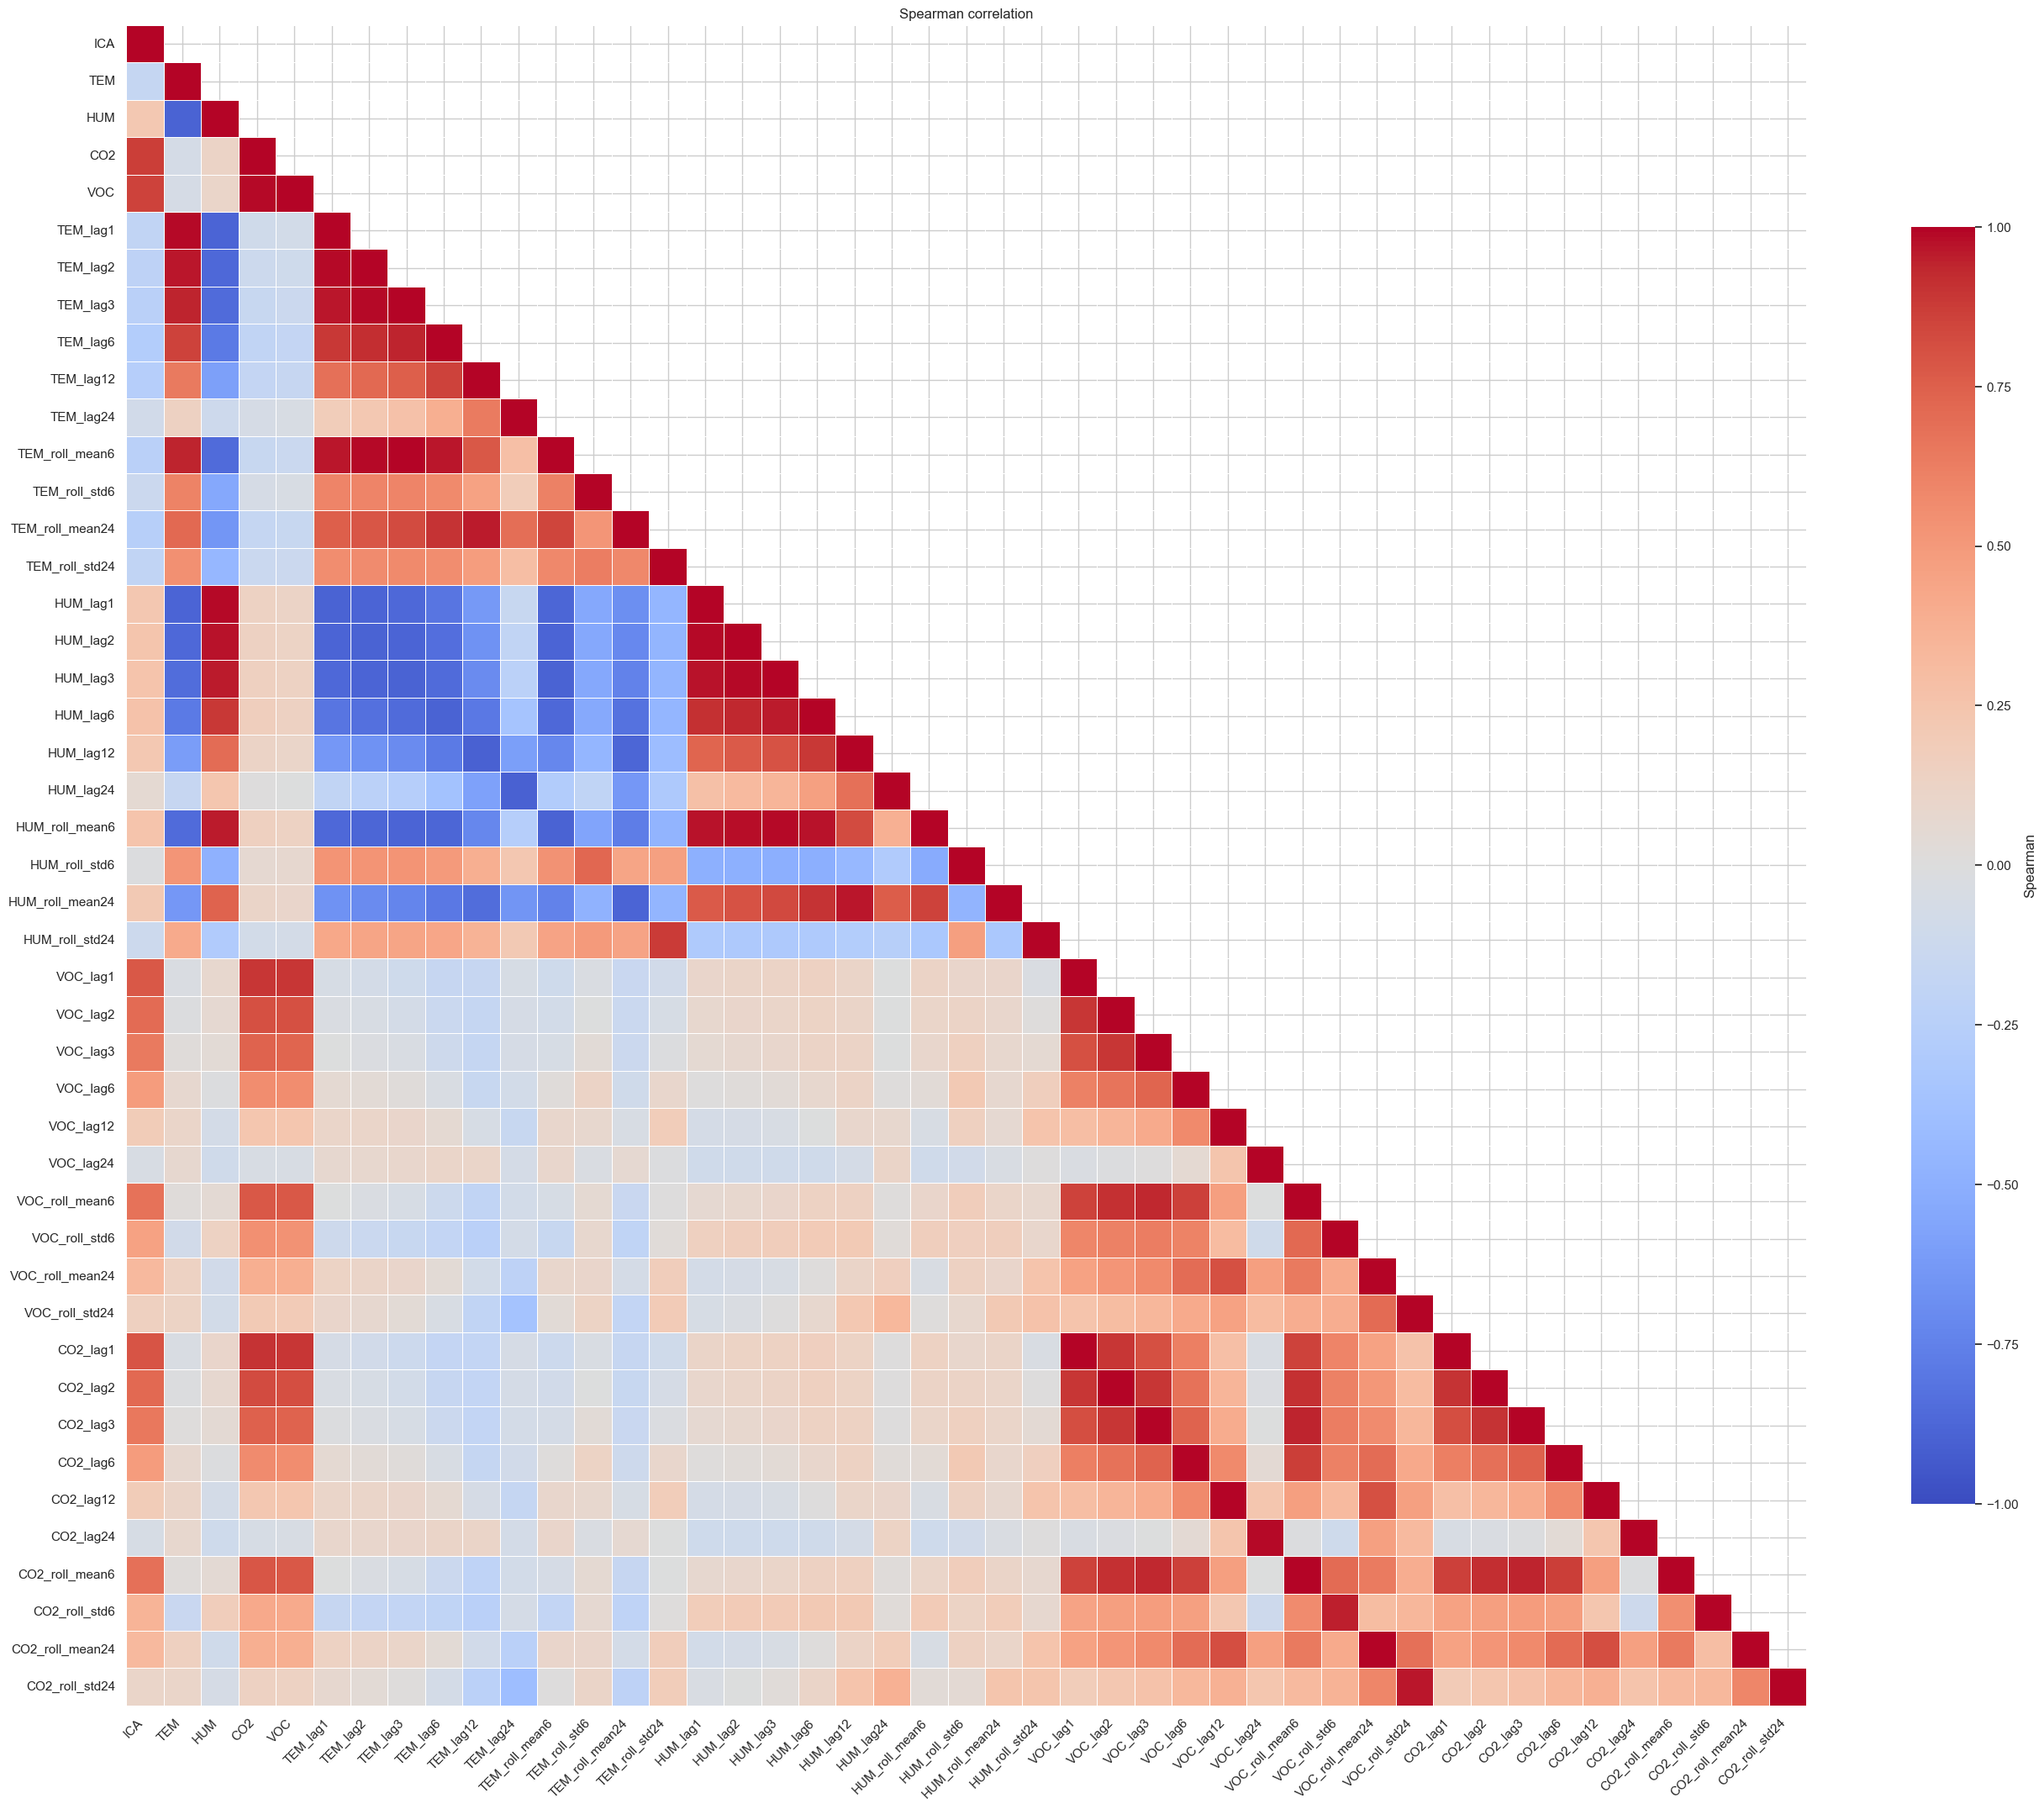

station:  MHH


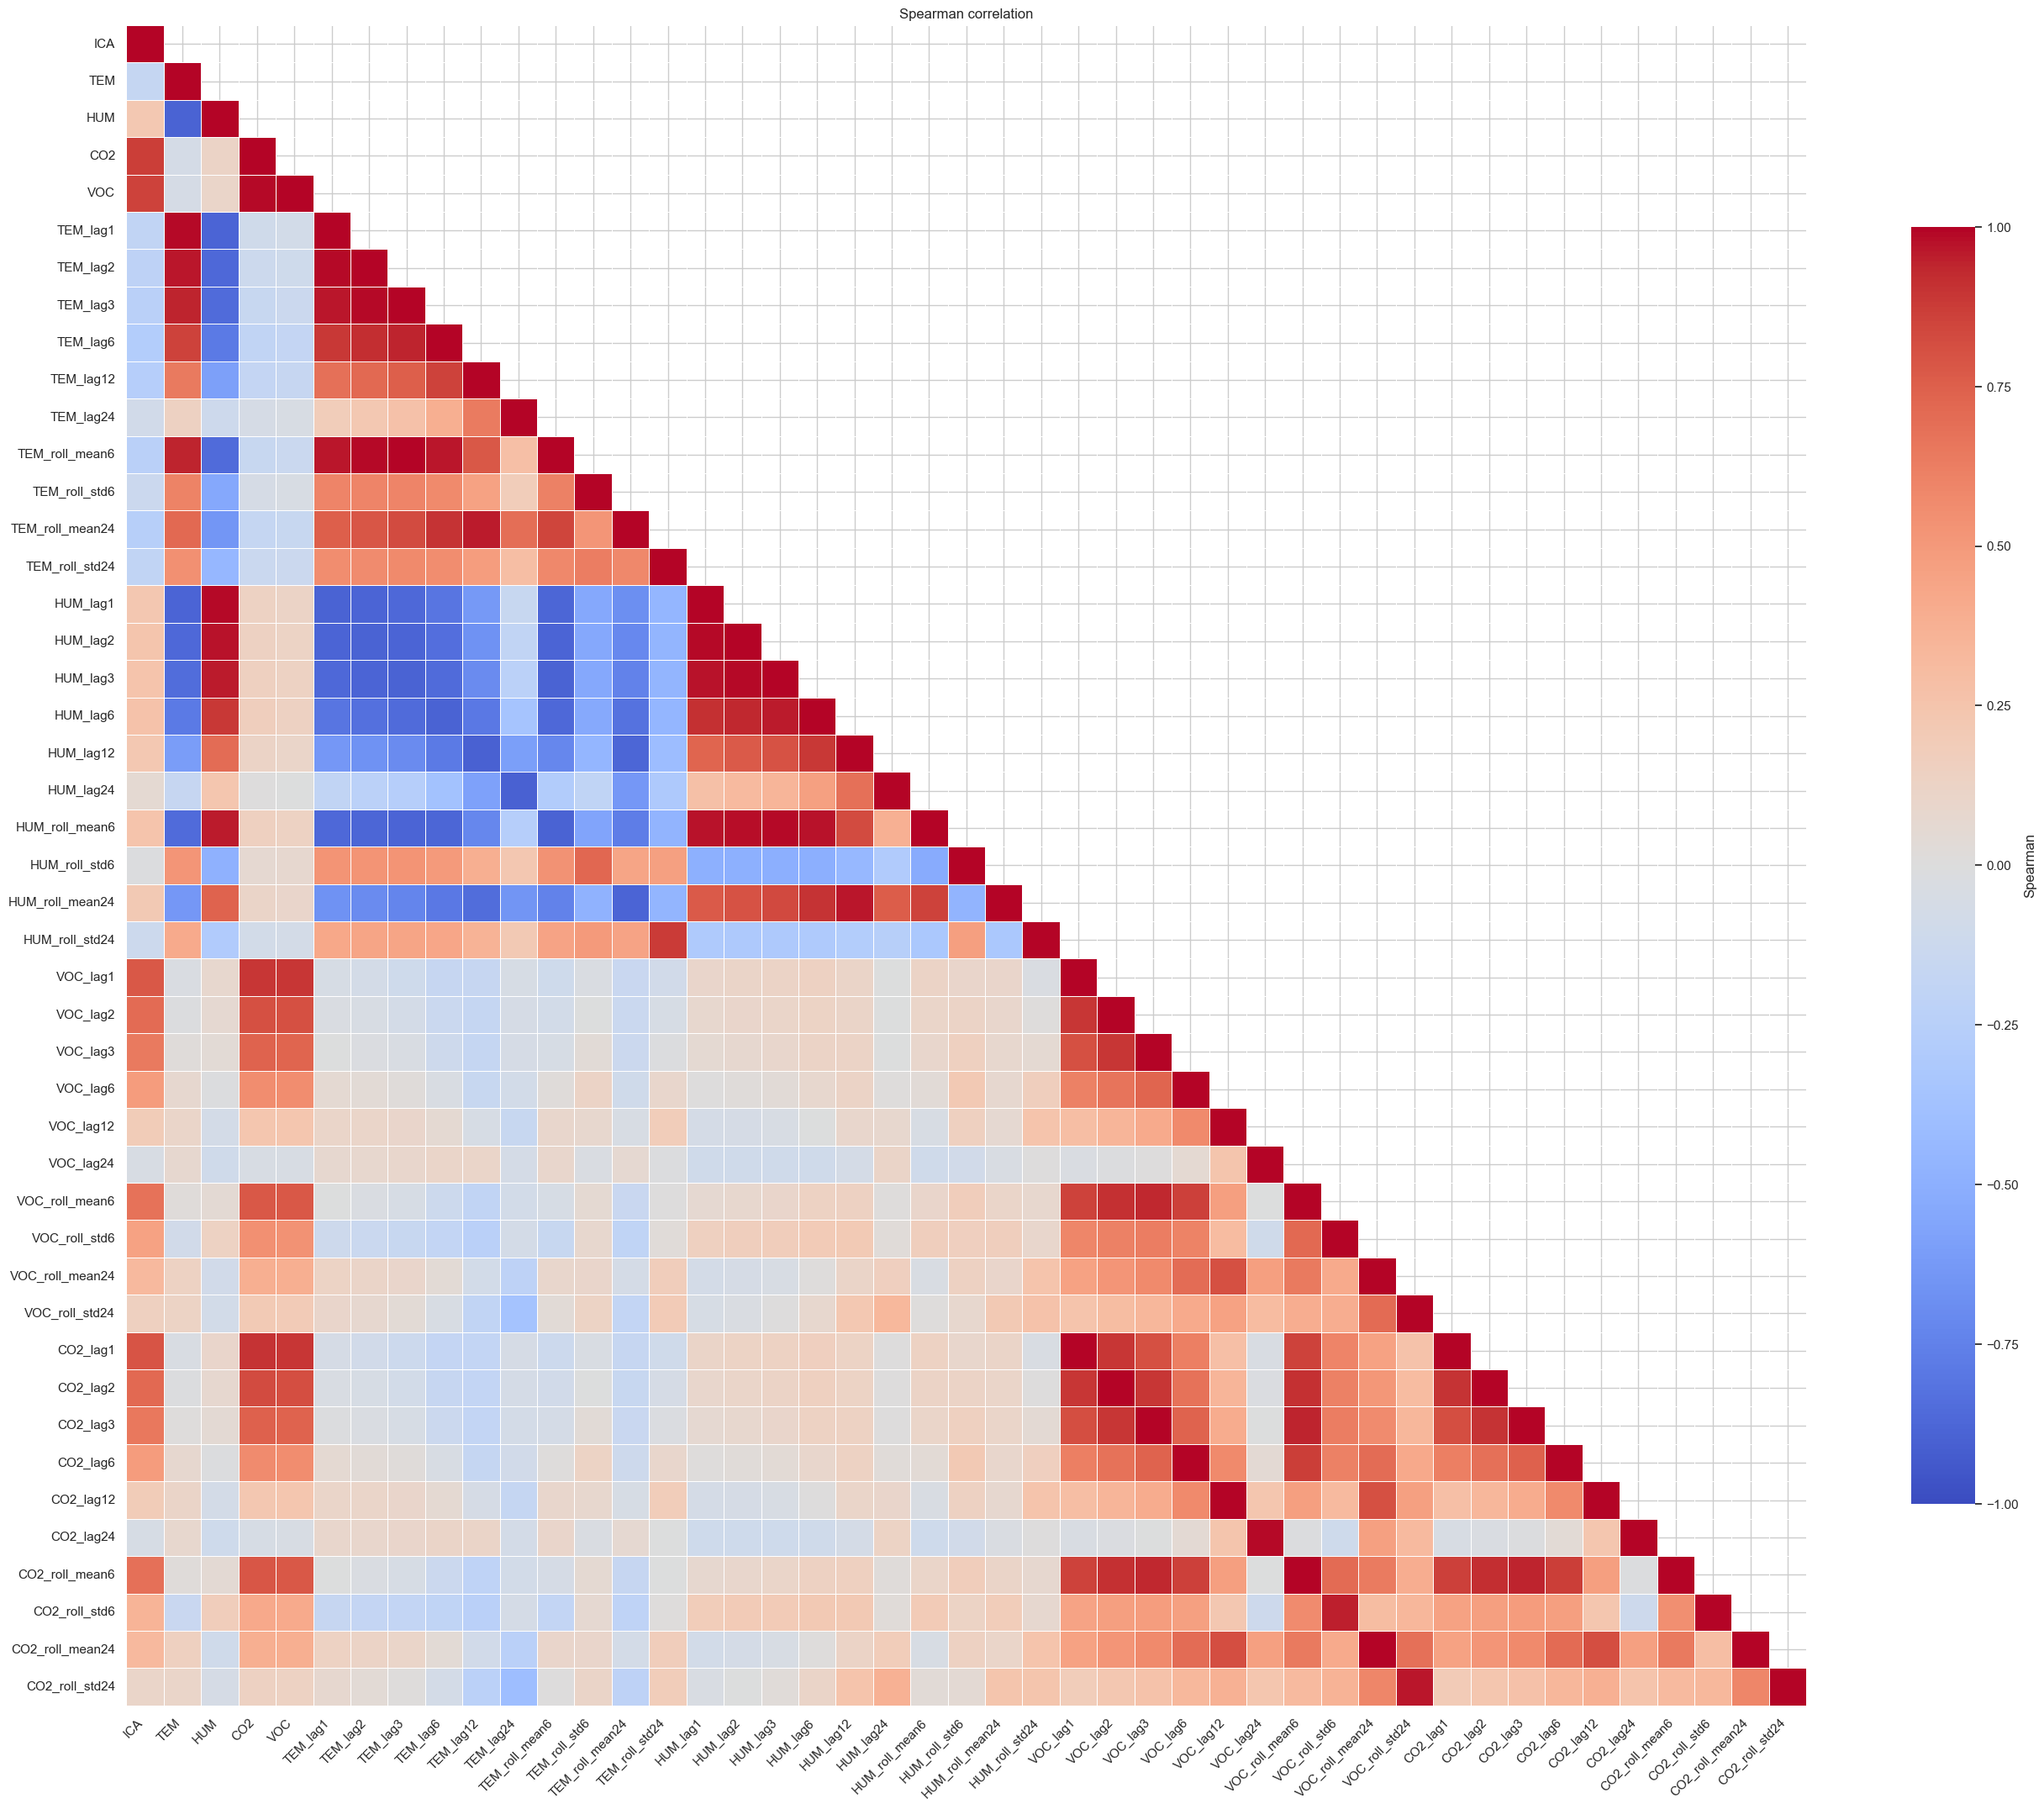

station:  USAM


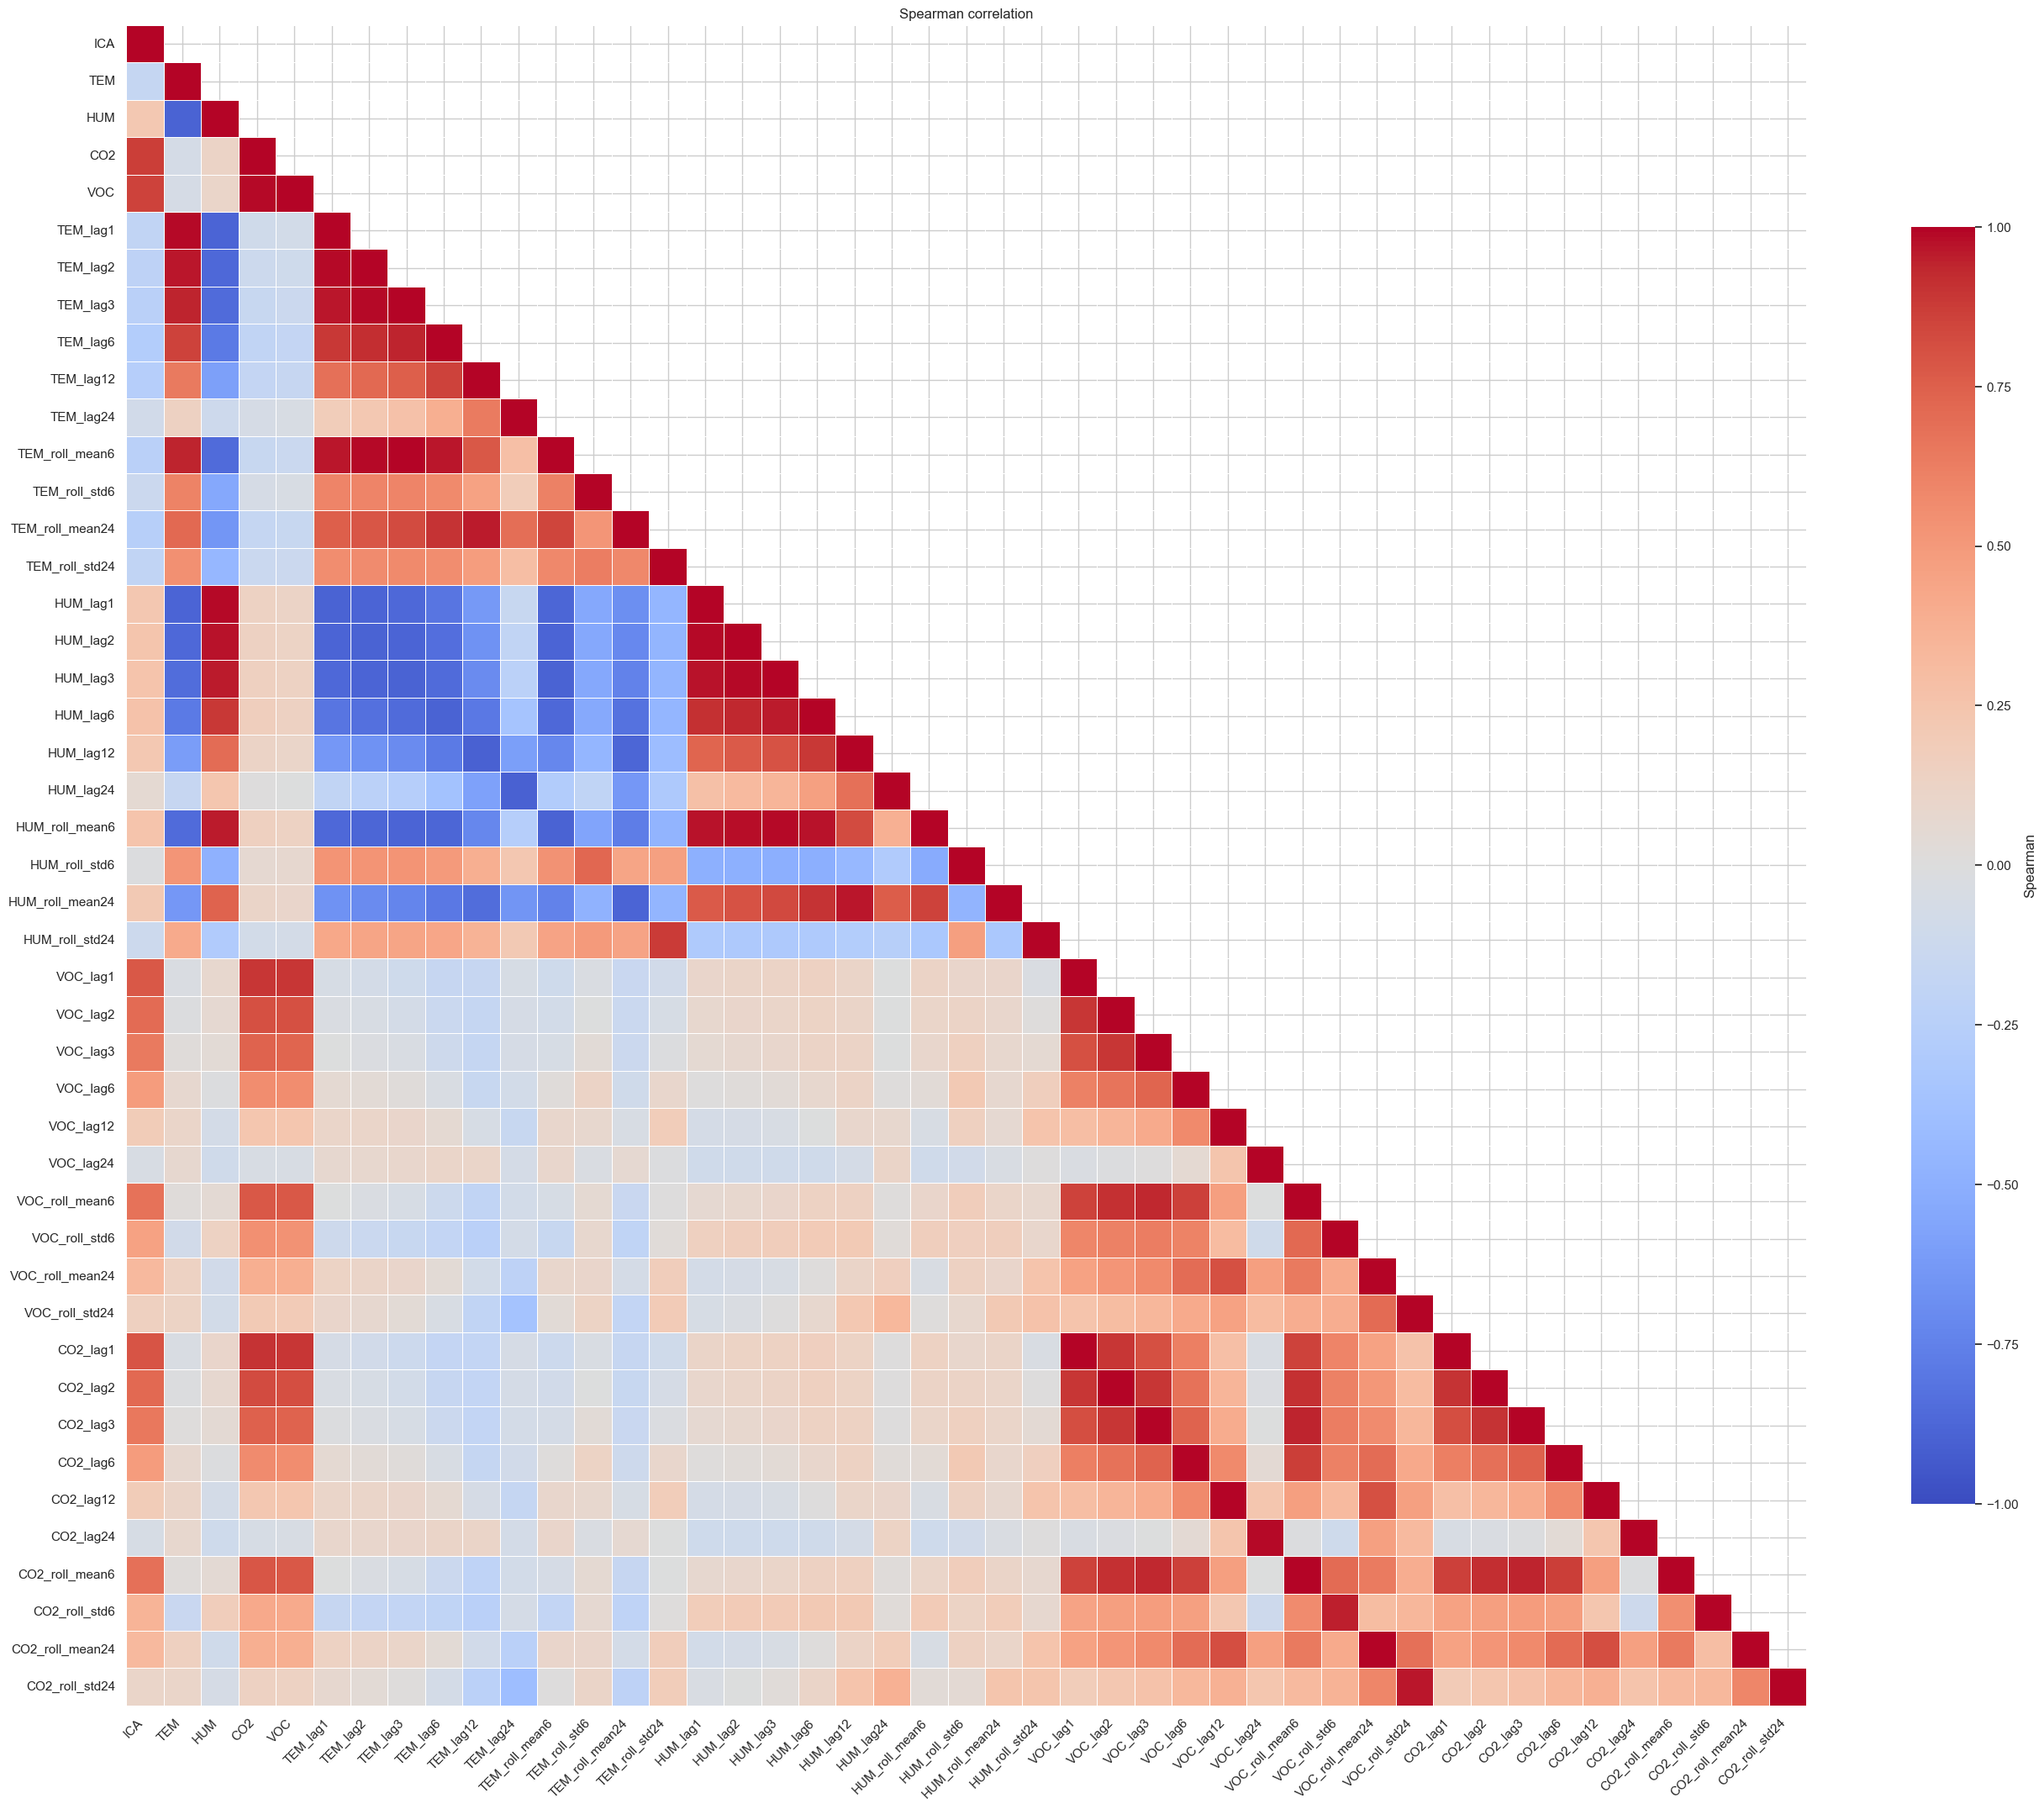

station:  UTEC


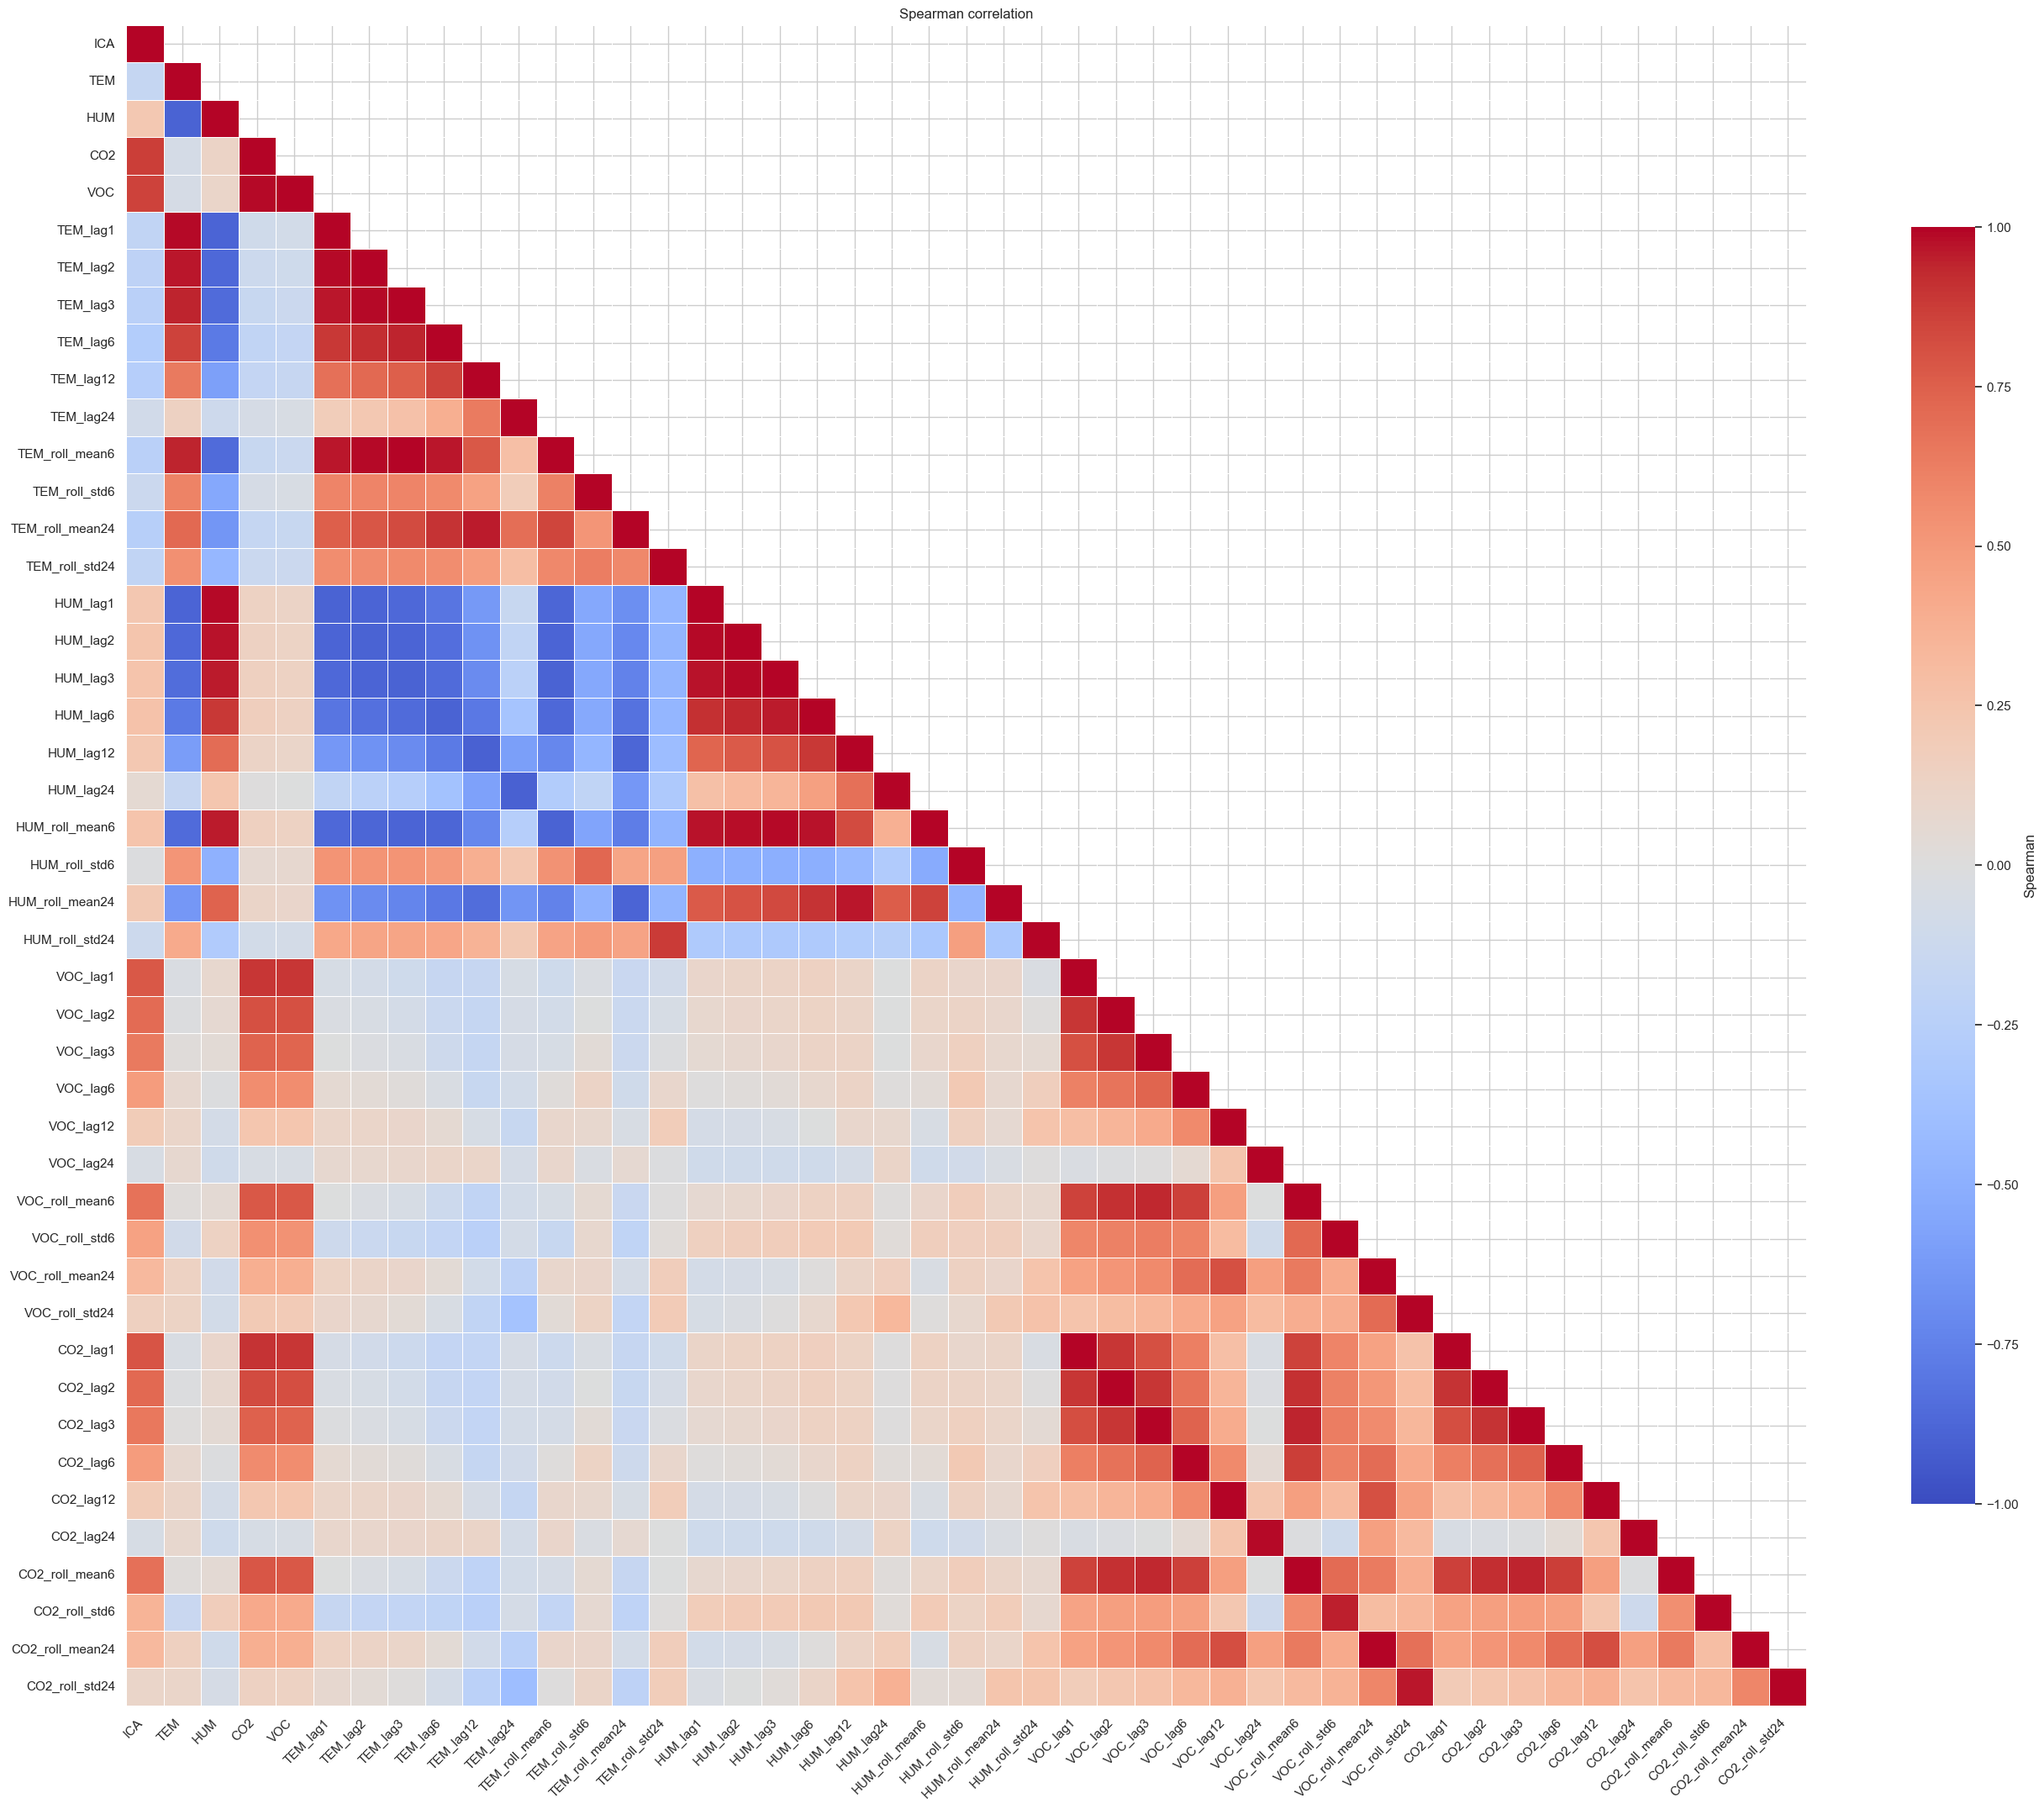

In [12]:
stations = ['APLAN', 'MHH', 'USAM', 'UTEC']
# stations = ['APLAN','MHH','PFM', 'PGB', 'PLIB', 'USAM', 'UTEC']

for station in stations:
    filepath = os.path.join(generalpath, f"{station}_processed_features.parquet")
    df = pd.read_parquet(filepath)
    print("station: ", station)
    plot_correlations_features(data.filter(regex=r"^(?!hour_|dow_|is_weekend)"))
